# Модель предсказания CTR на рекламное объявление.

- Автор: Серов Константин
- Дата: 16.10.2026

## Цель

**Цель:** 

Построение модели бинарной классификации, которая предсказывает вероятность клика (CTR) на рекламное объявление. Проведение калибровки этой модели, чтобы обеспечить соответствие между предсказанными вероятностями и фактической частотой кликов.

## Данные
Команда аналитиков Advandex подготовила датасет `ds_s16_ad_click_dataset`. Данные были собраны из систем показа рекламы и логирования взаимодействий пользователей с рекламными баннерами.

Что важно знать про данные:
 - **Период агрегации.** Данные содержат информацию о показе рекламных баннеров и действиях пользователей за фиксированный временной промежуток.
 - **Формат данных.** Данные представлены в виде готовой аналитической витрины. Это означает, что для каждого показа рекламного баннера уже рассчитаны и собраны в одну строку все необходимые для моделирования признаки.
 - **Структура.** Каждая строка соответствует одному уникальному событию показа рекламы. Все признаки предварительно обработаны и представлены в виде числовых и категориальных значений.
 - **Данные анонимизированы.** В этом проекте используется датасет, который прошёл предварительную обработку для обеспечения анонимности и сохранности данных. 
 
**Признаки в датасете:**

Идентификаторы и временные метки:
- `id` — уникальный идентификатор записи о показе баннера;
- `hour` — час, в который был показан баннер, в формате `YYMMDDHH`.

Характеристики рекламной площадки ( `Site` ):

- `site_id` — идентификатор веб-сайта, на котором был показан баннер;
- `site_domain` — домен веб-сайта;
- `site_category` — тематическая категория веб-сайта.

Характеристики рекламируемого приложения ( `App` ):

- `app_id` — идентификатор рекламируемого мобильного приложения;
- `app_domain` — домен рекламируемого приложения;
- `app_category` — категория рекламируемого приложения.

Характеристики устройства и соединения пользователя:

- `device_id` — идентификатор браузера или устройства;
- `device_ip` — IP-адрес устройства;
- `device_model` — модель устройства;
- `device_type` — тип устройства пользователя: например, смартфон, планшет, ПК;
- `device_conn_type` — тип сетевого соединения устройства: например, Wi-Fi, 3G, 4G.

Характеристики рекламного баннера и аукциона:

- `banner_pos` — позиция баннера на веб-странице;
- `C1` — анонимизированный признак, характеризующий контекст показа;
- `C14` — `C21` — группа анонимизированных признаков, описывающих параметры баннера, пользователя или аукциона.

Машинно-сгенерированные признаки (ML Features):

- `ml_feature_1`, `ml_feature_3` — `ml_feature_6`, `ml_feature_8` — `ml_feature_10` — числовые признаки, полученные в результате предварительной обработки и генерации новых признаков;
- `ml_feature_2`, `ml_feature_7` — категориальные признаки, полученные в результате предварительной обработки и генерации новых признаков.

**Целевая переменная:**

- `click` — бинарный признак, указывающий, был ли совершён клик по баннеру. `1` — клик был, `0` — клика не было.

## Структура проекта
1. Подготовка среды и загрузка данных;
2. Исследовательский анализ данных;
3. Разделение данных на выборки;
4. Предобработка данных - построение пайплайнов;
5. Отбор признаков;
6. Обучение базовой модели;
7. Подбор гиперпараметров;
8. Финальная модель;
9. Калибровка модели;
10. Оценка качества калибровки.
11. Финальный отчёт и выводы
12. Сохранение модели для продакшена.
---

## Подготовка среды и загрузка данных

### Подготовка библиотеки

- Устанавливаем пакеты

In [1]:
!pip install -q scikit-learn==1.6.1 phik mlxtend

- Импортируем необходимые библиотеки:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik
import sklearn

# Разбиение, кросс-валидация
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_score, GridSearchCV
)

# Предобработка
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, TargetEncoder

# Отбор признаков
from sklearn.feature_selection import VarianceThreshold, RFE
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

# Модели
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Калибровка
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator

# Метрики
from sklearn.metrics import (
    average_precision_score, log_loss, brier_score_loss,
    precision_score, recall_score, f1_score
)

# Сохранение/загрузка модели
import joblib

# Время
from time import time

- Создадим файл `requirements.txt` с фиксированными версиями всех пакетов:

In [3]:
!pip freeze > requirements.txt

- Зафиксируем значение параметра `random_state` для воспроизводимости случайной последовательности (результата). А также настроим некоторые параметры `pandas` для удобства отображения данных.

In [4]:
# Фиксируем значение параметра random_state
RANDOM_STATE = 49

# Настройка pandas
# Убираем ограниечение количества отображаемых столбцов датафрейма
pd.set_option('display.max_columns', None)

# Убираем ограниечение количества отображаемых строк датафрейма
pd.set_option('display.max_rows', None)

---

### Загрузка данных
- Загрузим данные датасета в датафрейм

In [5]:
df = pd.read_csv('/datasets/ds_s16_ad_click_dataset.csv')

- Познакомимся с данными: выведем размер датасета, первые несколько строк и информацию о типах столбцов. Проверим успешность загрузки данных.

In [6]:
# Размер датафрейма
df.shape

(50000, 34)

In [7]:
# Первые 5 строк датафрейма
df.head(15)

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,device_model,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21,ml_feature_1,ml_feature_2,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_7,ml_feature_8,ml_feature_9,ml_feature_10
0,1.005263e+19,1,14102100,1005,1,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,488a9a3e,31025cda,1,0,17614,320,50,1993,2,1063,-1,33,-0.996823,A,0.666588,0,0.817292,0.993275,Z,-0.619959,0.433666,0.274038
1,1.010597e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,75bb1b58,2ee63ff8,1,0,15701,320,50,1722,0,35,-1,79,-0.391309,C,5.146789,1,-0.883865,-0.825722,X,0.576526,-0.318558,-0.132851
2,1.012048e+19,0,14102100,1005,0,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,285263b0,d780319b,1,0,17914,320,50,2043,2,39,100084,32,-2.112732,D,7.169348,0,-0.859440,-0.338365,Y,-0.440047,-0.345412,0.340487
3,1.021995e+18,0,14102100,1005,0,85f751fd,c4e18dd6,50e219e0,39cfef32,d9b5648e,0f2161f8,a99f214a,18190986,f4fffcd0,1,0,21611,320,50,2480,3,297,100111,61,0.332707,A,-0.290708,1,0.062795,0.062934,Y,0.551982,0.733382,-0.198542
4,1.023455e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,b66e5482,a0f5f879,1,0,15702,320,50,1722,0,35,100084,79,1.166623,A,6.319134,1,-0.675276,0.797144,X,0.640827,0.297955,-0.136909
5,1.037910e+19,1,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,b761b0b6,711ee120,1,0,15702,320,50,1722,0,35,100084,79,-0.386621,D,-2.561220,1,-0.327084,0.997424,Y,-0.718630,0.063355,0.118050
6,1.046962e+19,0,14102100,1005,0,543a539e,c7ca3108,3e814130,ecad2386,7801e8d9,07d7df22,a99f214a,f493aa05,24f6b932,1,0,20596,320,50,2161,0,35,-1,157,-1.029484,B,0.616779,0,-0.088135,-0.484160,Y,0.390766,0.399371,0.278207
7,1.048718e+19,0,14102100,1005,0,85f751fd,c4e18dd6,50e219e0,fbbccc58,2347f47a,0f2161f8,a99f214a,e2b9f6ab,8f1db0bc,1,2,20345,300,250,2331,2,39,-1,23,-1.412949,A,0.667451,0,0.010914,-0.607470,Y,0.216093,0.746051,0.439438
8,1.056080e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,4cd357a7,c144e605,1,0,15708,320,50,1722,0,35,-1,79,-1.841339,C,-8.415390,0,-0.774189,-0.957543,Z,-0.230077,0.574167,-0.054031
9,1.081451e+19,1,14102100,1005,1,e59ef3fc,0a4015b2,335d28a8,ecad2386,7801e8d9,07d7df22,a99f214a,35d0456e,be74e6fe,1,0,18993,320,50,2161,0,35,100105,157,-1.098406,D,6.310419,0,1.930692,-0.980213,Y,-0.354278,0.372335,0.321687


In [8]:
# Общая информация о датафрейме
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                50000 non-null  float64
 1   click             50000 non-null  int64  
 2   hour              50000 non-null  int64  
 3   C1                50000 non-null  int64  
 4   banner_pos        50000 non-null  int64  
 5   site_id           50000 non-null  object 
 6   site_domain       50000 non-null  object 
 7   site_category     50000 non-null  object 
 8   app_id            50000 non-null  object 
 9   app_domain        50000 non-null  object 
 10  app_category      50000 non-null  object 
 11  device_id         50000 non-null  object 
 12  device_ip         50000 non-null  object 
 13  device_model      50000 non-null  object 
 14  device_type       50000 non-null  int64  
 15  device_conn_type  50000 non-null  int64  
 16  C14               50000 non-null  int64 

In [9]:
# Информация о пропусках в датафрейме
def df_misses_info(df):
    # Абсолютное кол-во пропусков df
    missing_count = df.isna().sum()
    
    # Относительное кол-во пропусков df
    missing_percent = (df.isna().mean() * 100).round(2)
    
    # Собираем в одну таблицу для наглядности
    missing_info = pd.DataFrame({
        'count': missing_count,
        'percent': missing_percent
    })
    
    return missing_info.sort_values('percent', ascending=False)

# Выводим информацию о пропусках в df
df_misses = df_misses_info(df)  
df_misses

,count,percent
id,0,0.0
ml_feature_2,0,0.0
C17,0,0.0
C18,0,0.0
C19,0,0.0
C20,0,0.0
C21,0,0.0
ml_feature_1,0,0.0
ml_feature_3,0,0.0
click,0,0.0


Проверим датасет на наличие полных дублей и повторов по `id`:

In [10]:
print(f'Полных дублей: {df.duplicated().sum()}')
print(f"Повторов по id: {df['id'].duplicated().sum()}")

Полных дублей: 0
Повторов по id: 0


Итак, датасет содержит:
- 34 столбцов (33 признаков + целевая переменная `click`) и 50000 строк;
- Типы: 8 столбцов - `float64`, 15 - `int64`, 11 - `object`;
- Датасет занимает 13.0+ MB;
- Пропуски в датафрейме отсутствуют;
- Дубли не обнаружены.

Типы данных формально корректны везде. Далее сделаем более подробный анализ признаков.

Явных пропусков (`NaN`) в данных нет, во всех 34 столбцах заполнены все 50000 значений, поэтому обработка пропусков на этапе анализа данных не требуется. Однако стоит добавить шаг заполнения пропусков в пайплайн, так как они могут появиться в новых данных. 

---

## Исследовательский анализ данных (EDA)

### Базовая информация

Мы посмотрели типы данных столбцов (`dtype`). Тип данных не всегда совпадает с типом признака по смыслу. Например, в целочисленном столбце могут храниться коды категорий. Чтобы это проверить, выведем для каждого столбца тип данных и число уникальных значений

In [11]:
# Тип данных и число уникальных значений в каждом столбце
pd.DataFrame({
    'dtype': df.dtypes,
    'nunique': df.nunique()
}).sort_values('nunique')

,dtype,nunique
ml_feature_4,int64,2
click,int64,2
ml_feature_7,object,3
device_conn_type,int64,4
device_type,int64,4
C18,int64,4
ml_feature_2,object,5
C1,int64,7
banner_pos,int64,7
C15,int64,8


Всего в датафрейме 50000 объектов и 34 столбца, включающих целевую переменную `click`, служебный идентификатор `id` и 32 потенциальных признака. Если смотреть на тип данных, числовых столбцов 23 (8 - `float64` и 15 `int64`), а строковых 11. Однако по смыслу картина другая: 
- непрерывных числовых признаков только 7 (`ml_feature_1, 3, 5, 6, 8, 9, 10`) - у каждого из них 50000 уникальных дробных значений; 
- 12 целочисленных столбцов (`device_type`, `device_conn_type`, `C1`, `banner_pos` И `C14-C21`) на деле категориальные, по описанию это типы, позиции и анонимизированные параметры, значений у которых относительно общего объёма немного (от 4 до 1497). Арифметические опреации над такими значениями не будут иметь смысла;
- Все 11 столбцов типа `object` тоже категориальные. Число категорий в них меняется от 3 до 41455;
- `ml_feature_4` имеет тип `int64` и указан как числовой, но принимает всего два значения (0 и 1) и является бинарным признаком, но можно отнести к категориальному;
- `hour` - временная метка, имеет 240 уникальных часов, что соответствует 10 суткам. Можно отнести к категориальному типу;
- `id` - уникальный идентификатор, который будет удалён из датафрейма в первую очередь.

Стоит посмотреть на точные границы временной метки `hour`:

In [12]:
print(f"Первый час периода: {df['hour'].min()}")
print(f"Последний час периода: {df['hour'].max()}")

Первый час периода: 14102100
Последний час периода: 14103023


То есть первый час - это 21 октября 2014, 00 часов, а последний - 30 октября 2014 в 23 часа, что действиетльно соответствует 10 суткам. При этом уникальных значений `hour` ровно 240, что равно 10 х 24, значит внутри периода нет пропущенных часов.

**Что известно о пользователях и рекламе**
- Одна строка соответствует одному показу баннера, а данные охватывают 10 суток (240 часов).
- О пользователе известны только устройство и соединение: идентификатор устройства, IP-адрес, модель, тип устройства и тип сети. Данных о самом человеке в датасете нет.
- О рекламе известно, где она показана (сайт или приложение, их домены и категории), как показана (позиция баннера и анонимизированные С-признаки) и когда (`hour`). 

---

### Целевая переменная
Целевая переменная `click` - бинарный признак, указывающий, был ли совершён клик по баннеру.

Стоит проанализировать, сколько показов закончилось кликом, а сколько нет, в абсолютных числах и процентных долях. В описании проекта основной метрикой названа `PR-AUC`, потому что клики редки. Анализ целевой переменной позволит проверить это на данных и увидеть, насколько сильный дисбаланс.

In [13]:
# Кол-во и доля каждого класса целевой переменной
click_info = pd.DataFrame({
    'count': df['click'].value_counts(),
    'percent': (df['click'].value_counts(normalize=True) * 100).round(2)
})

click_info

,count,percent
0,41397,82.79
1,8603,17.21


In [14]:
# Доля кликов
ctr_mean = df['click'].mean()
print(f'Доля кликов: {ctr_mean:.4f}')

Доля кликов: 0.1721


Для наглядности выполним визуализацию:

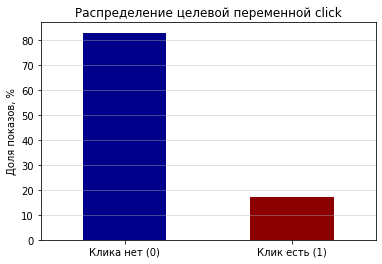

In [15]:
# Столбччатая диаграмма целевой переменной click
click_info['percent'].plot(kind='bar', color=['darkblue', 'darkred'])
plt.xticks([0, 1], ['Клика нет (0)', 'Клик есть (1)'], rotation=0)
plt.ylabel('Доля показов, %')
plt.title('Распределение целевой переменной click')
plt.grid(axis='y', alpha=0.5)
plt.show()

Клик произошёл в 8603 показах из 50000, то есть в 17.21% случаев, а 41397 показов (82.79%) остались без клика. Классы несбалансированы. При таком соотношении Accuracy здесь неинформативна, F1 также чувствительна к дисбалансу классов. Поэтому выбор PR-AUC в качестве основной метрики подтверждается данными.

Доля кликов (средний CTR) составляет 0.1721. По сути это PR-AUC модели, которая угадывает случайно, поэтому наша модель должна будет показать результат выше.

### Анализ признаков
Определим, все ли признаки нужны для обучения модели.

Для начала проверим признаки на соответствие трём критериям:
- **Константный** признак принимает одно значение и не различает объекты. 
- **Квази-константный** почти всегда принимает одно значение, поэтому несёт мало информации. 
- **Уникальный признак**, наоборот, у каждой строки свой: модели не на чем обобщать, и она может только запомнить обучающие строки. Для этого считаем по каждому столбцу долю уникальных значений и долю самого частого значения.

Посчитаем по каждому столбцу долю уникальных значений и долю самого частого значения.

In [16]:
# Доля уникальных значений и доля самого частого значения
features_info = pd.DataFrame({
    'nunique': df.nunique(),
    'unique_share': (df.nunique() / len(df)).round(3),
    'top_share': [round(df[col].value_counts(normalize=True).iloc[0], 3) for col in df.columns]
}).sort_values('nunique', ascending=False)
features_info

,nunique,unique_share,top_share
id,50000,1.000,0.000
ml_feature_1,50000,1.000,0.000
ml_feature_9,50000,1.000,0.000
ml_feature_8,50000,1.000,0.000
ml_feature_6,50000,1.000,0.000
ml_feature_5,50000,1.000,0.000
ml_feature_3,50000,1.000,0.000
ml_feature_10,50000,1.000,0.000
device_ip,41455,0.829,0.005
device_id,8580,0.172,0.824


- **Константных** признаков в датасете нет. Минимальное число уникальных значений равно двум (`ml_feature_4` и целевая переменная `click`), а доля самого частого значения ни у одного столбца не достигает 1.
- Для категориальных признаков обычно используют порог доли наиболее частого значения. Например, если один уровень встречается более чем в 90% случаев, признак можно считать **квази-константным**. Порог 0,9 превышают четыре признака: `C16` (0.946), `C15` (0.936), `device_type` (0.921) и `C1` (0.917). Близки к порогу `device_conn_type` (0.860) и `device_id` (0.824). На этом этапе эти признаки оставляем. На редкие категории у них приходится от 5 до 8% строк, то есть примерно 2700–4150 показов, и этого достаточно, чтобы оценить по ним долю кликов. Если в редких категориях она заметно отличается от средней, признак полезен, несмотря на перекос. Позже проверим это по связи с целевой переменной.
- Долю **уникальных** значений 1.0 имеют восемь столбцов, но причина у них разная. id — служебный номер записи, он не несёт информации и удаляется. Семь признаков `ml_feature_1, 3, 5, 6, 8, 9, 10` - непрерывные числовые величины. Для них уникальность каждого значения естественна и недостатком не является: значения упорядочены и сравнимы между собой, поэтому модель может по ним обобщать. Критерий уникальности применим только к идентификаторам и категориальным признакам. 
- `device_ip`: категориальный признак, имеющий 41455 значений на 50000 строк (доля 0.829), самый частый адрес встречается в 0.5% показов. Статистики по отдельным адресам мало, поэтому признак является кандидатом на удаление, аналогично `id`. Посмотрим, какой процент ip-адресов встречается только один раз:

Стоит избавиться от всех айди и квази-айди признаков, так как они не помогут модели предсказывать клики на новых данных. Это также каасается идентификаторов площадок и устройств: `site_id` (1160 значений), `site_domain` (1013), `app_id` (976), `app_domain` (67) и `device_id` (8580). Модель будет работать в рекламном аукционе, где постоянно появляются новые сайты, приложения и устройства. Связь клика с конкретным идентификатором на них не переносится: если модель запомнит, что на определённом сайте кликают чаще, на новом сайте это знание бесполезно. К тому же у большинства значений этих признаков всего несколько показов, и надёжно оценить по ним долю кликов нельзя. Для `device_id` дополнительно характерен сильный перекос: одно значение занимает 82.4% строк.

In [17]:
# Процент ip-адресов, которые встречаются в датасете только 1 раз
ip_counts = df['device_ip'].value_counts()
print(f"Адресов, встретившихся один раз: {(ip_counts == 1).mean():.1%}")

# Процент строк в датасете, в которых встречаются уникальные ip-адреса
print(f'Строк с уникальными адресами: {(ip_counts == 1).sum() / len(df):.1%}')

Адресов, встретившихся один раз: 92.6%
Строк с уникальными адресами: 76.8%


Из 41455 адресов 92.6% встречаются в датасете только один раз, на эти адреса приходится 76.8% всех строк. То есть повторяющихся адресов всего около 7% и они покрывают меньше четверти данных. Признак стоит удалить.

- Столбец `hour` как число смысла не имеет: между 23:00 и следующим часом значение прыгает с 14102123 на 14102200. Полезной информации в нём является время суток (час) и день недели, их и стоит вытащить, а сам столбец удалить.

Разделим `hour` на `hour_of_day` (час суток) и `day_of_week` (день недели):

In [18]:
# Преобразуем hour в дату и время
hour_dt = pd.to_datetime(df['hour'].astype(object), format='%y%m%d%H')

In [19]:
# Сохраняем оригинальный датафрейм
df_original_hour = df.copy()

In [20]:
# Излекаем час суток и день недели
df['hour_of_day'] = hour_dt.dt.hour
df['day_of_week'] = hour_dt.dt.day_of_week

# Проверяем кол-во уникальных значений часов и дней недели
df[['hour_of_day', 'day_of_week']].nunique()

hour_of_day    24
day_of_week     7
dtype: int64

---

- Разделение по категориям

Столбцы `id`, `device_ip` и `hour` не будем включать в разделение по категориям, так как они будут удалены. `hour` заменяем на `hour_of_day` (час суток) и `day_of_week`. 

К **числовым** признакам отнесём семь непрерывных призаков `ml_feature_1, 3, 5, 6, 8, 9, 10`. Всего 7.

Остальные 19 признаков **категориальные**. Это все столбцы типа `object` (`site_category`, `app_category`, `device_model`, `ml_feature_2`, `ml_feature_7` и новые `hour_of_day` и `day_of_week`) и двенадцать целочисленных столбцов типа `int64` (`C1`, `banner_pos`, `device_type`, `device_conn_type`, `C14–C21` и бинарный `ml_feature_4`).

Целочисленные нужно преобразовать в `object`, чтобы кодирование `TargetEncoder` прошло корректно. 

Сформируем списки по категориям:

In [21]:
# Числовые признаки
num_features = ['ml_feature_1', 'ml_feature_3', 'ml_feature_5',
                'ml_feature_6', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10']

# Категориальные признаки
cat_features = ['C1', 'banner_pos', 'device_type', 'device_conn_type',
                'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21',
                'site_category', 'app_category',
                'device_model', 'ml_feature_2', 'ml_feature_4', 
                'ml_feature_7', 'hour_of_day', 'day_of_week']

# Сохраним типы до преобразования
cat_types_befor = df[cat_features].dtypes

# Целочисленные коды категорий приводим к object
df[cat_features] = df[cat_features].astype(object)

# Сформируем талицу "до" изменений и "после"
pd.DataFrame({
    'до': cat_types_befor,
    'после': df[cat_features].dtypes
})

,до,после
C1,int64,object
banner_pos,int64,object
device_type,int64,object
device_conn_type,int64,object
C14,int64,object
C15,int64,object
C16,int64,object
C17,int64,object
C18,int64,object
C19,int64,object


In [22]:
# Проверяем кол-во столбцов по категорим
print(f'Числовых: {len(num_features)}, категориальных: {len(cat_features)}')

Числовых: 7, категориальных: 20


---

- проведём первичнй отбор

Были определены следующие кандидаты на удаление: `id` - уникальный идентификатор, `device_ip` - практически уникальный, `hour` заменили на `day_of_week` и `hour_of_day`, а также идентификаторы площадок, приложений и устройств `site_id`, `site_domain`, `app_id`, `app_domain` и `device_id`. Они не переносятся на новые сайты, приложения и устройства.

In [23]:
# Перед удалением признаков сохраним текущий вариант датафрейма
df_before_initial_selection = df.copy()

In [24]:
# Первичный отбор: удаляем id, device_ip и hour, а также идентификаторы площадок,
# приложений и устройств: site_id, site_domain, app_id, app_domain, device_id
df = df.drop(columns=['id', 'device_ip', 'hour',
                      'site_id', 'site_domain', 'app_id', 'app_domain', 'device_id'])

In [25]:
# Проверяем
print(f'Кол-во столбцов в датафрейме: {df.shape[1]}')
print(f'Кол-во признаков по категориям + целевая переменная: {len(num_features) + len(cat_features) + 1}')

Кол-во столбцов в датафрейме: 28
Кол-во признаков по категориям + целевая переменная: 28


---

В ходе анализа признаков мы разделили их на числовые и категориальные. К **числовым** отнесены семь непрерывных призаков `ml_feature_1, 3, 5, 6, 8, 9, 10`. Всего 7. **Категориальных** признаков 20: это все столбцы типа `object` (`site_category`, `app_category`, `device_model`, `ml_feature_2`, `ml_feature_7` и новые `hour_of_day` и `day_of_week`), двенадцать целочисленных столбцов типа `int64` (`C1`, `banner_pos`, `device_type`, `device_conn_type`, `C14–C21`) и бинарный `ml_feature_4`.

Целочисленные коды категорий приведены к типу `object` 

На этапе первичного отбора удалены столбцы: `id`, `device_ip`, `site_id`, `site_domain`, `app_id`, `app_domain`, `device_id` и `hour`, полезная информация из которого была перенесена в два других признака (`hour_of_day` и `day_of_week`).

Квази-константные признаки сохранены, нужно проверить их корреляционную связь с цеевой переменной. 

После отбора в датафрейме осталось 27 признаков и целевая переменная `click`

---

### 5.4 Анализ пропущенных значений

Проверка на наличие явных пропусков показала их полное отсутствие в датафрейме. Для чистоты прогоним текущую версию датафрейма `df` через функцию `df_misses_info()`:

In [26]:
# Проверка на наличие пропусков в датафрейме
df_misses_info(df)['count'].sum()

0

На данный момент в датафрейме отсутствуют явные пропуски. Однако, это не означает, что они абсолютно точно не появятся в будущем. Пайплайн подготовки данных должен это учитывать и знать, как их обрабатывать:
- для числовых признаков будем использовать медиану. Среднее может сдвигаться выбросами, а медиана к ним устойчива.
- категориальные признаки можно помечать отдельной категорией `missing`. Если заполнять пропуски модой, показы без данных смешаются с этой категорией и исказят её долю кликов. С отдельной категорией пропуски не повлияют на остальные. 

Также нужно учитывать вероятность присутствия в данных неявных пропусков. При первичном анализе датафрейма в столбце `C20` вызвали вопросы значения `-1` - посмотреим подробнее.

In [27]:
# Самые частые значения C20 и их доли
print(df['C20'].value_counts(normalize=True).head(5))

-1         0.46886
 100084    0.06018
 100148    0.04442
 100111    0.04220
 100077    0.03916
Name: C20, dtype: float64


In [28]:
# Доля кликов
c20_is_minus = df['C20'] == -1
print(df.groupby(c20_is_minus)['click'].mean())

C20
False    0.154799
True     0.191614
Name: click, dtype: float64


Значение `-1` встречается в `C20` чаще всех остальных. На него приходится 46.9% строк. Следующее по частоте значение (`100084`) занимает лишь 6.0%. Доля кликов у показов с `-1` сотавляет 0.192, у остальных 0.155. Разница около 3.7 процентов, то есть `-1` связано с более высокой вероятностью клика и несёт полезную информацию. Смысл этого значения неизвестен, поэтому заменить его медианой или модой будет некорректно. Оставляем как есть.

---

### 5.5 Анализ категориальных признаков
- Определим, сколько уникальных значений в каждом категориальном признаке:

In [29]:
# Число уникальных значений в каждом категориальном признаке
cat_nunique = df[cat_features].nunique().sort_values()
cat_nunique

ml_feature_4           2
ml_feature_7           3
device_type            4
device_conn_type       4
C18                    4
ml_feature_2           5
C1                     7
day_of_week            7
banner_pos             7
C15                    8
C16                    9
site_category         18
app_category          22
hour_of_day           24
C21                   59
C19                   64
C20                  149
C17                  387
C14                 1497
device_model        2521
dtype: int64

- из теории мы знаем, чтобы избежать проблем с памятью и вычислительными ресурсами, алгоритм `One-Hot Encoding` стоит применять только в тех случаях, когда количество уникальных категорий невелико - до 10–15 категорий (точный порог зависит от задачи и ресурсов). 

В качестве порога будем использовать кол-во уникальных значений признака `hour_of_day` (24), так как дальше идёт резкий скачок в кол-ве уникальных значений - в данных есть естественный разрыв. 

In [30]:
# Определим константу максимального количества уникальных значений признака для применения OHE
OHE_MAX_CATEGORIES = df['hour_of_day'].nunique()

# Сформируем таблицу с распределением метода кодирования признаков
cat_info = pd.DataFrame({
    'nunique': cat_nunique,
    'encoding': np.where(cat_nunique <= OHE_MAX_CATEGORIES, 'OHE', 'Target Encoding')
})
cat_info

,nunique,encoding
ml_feature_4,2,OHE
ml_feature_7,3,OHE
device_type,4,OHE
device_conn_type,4,OHE
C18,4,OHE
ml_feature_2,5,OHE
C1,7,OHE
day_of_week,7,OHE
banner_pos,7,OHE
C15,8,OHE


Сформируем списки:

In [31]:
ohe_features = cat_info[cat_info['encoding'] == 'OHE'].index.to_list()
te_features = cat_info[cat_info['encoding'] == 'Target Encoding'].index.to_list()

print(f'OHE ({len(ohe_features)}): {ohe_features}')
print(f'Target Encoding ({len(te_features)}): {te_features}')

OHE (14): ['ml_feature_4', 'ml_feature_7', 'device_type', 'device_conn_type', 'C18', 'ml_feature_2', 'C1', 'day_of_week', 'banner_pos', 'C15', 'C16', 'site_category', 'app_category', 'hour_of_day']
Target Encoding (6): ['C21', 'C19', 'C20', 'C17', 'C14', 'device_model']


Число уникальных значений в 20 категориальных признаках меняется от 2 до 2521. Был выбран порог равный 24 -  кол-во уникальных значений в признаках, к которым можно применить `OHE`. В итоге `OHE` применяется к 14 признакам. Остальные 6 признаков имеют высокую кардинальность и будут закодированы `Target Encoding`.

---

### 5.6 Анализ выбросов и распределений

- Проверим, есть ли явные выбросы в числовых признаках.

К ним относятся 7 непрерывных признаков (`ml_feature_1, 3, 5, 6, 8, 9, 10`). `ml_feature_4` в анализ выбросов не берём, он бинарный.

In [32]:
# Описательные статистики числовх признаков
df[num_features].describe().T

,count,mean,std,min,25%,50%,75%,max
ml_feature_1,50000.0,-0.002445,1.000280,-4.631262,-0.677784,-0.003776,0.673534,3.793828
ml_feature_3,50000.0,-0.036381,5.792335,-9.999742,-5.059555,-0.056155,4.985939,9.999975
ml_feature_5,50000.0,0.034729,1.002116,-4.631853,-0.639829,0.028112,0.707594,4.230623
ml_feature_6,50000.0,0.022948,0.656690,-1.000000,-0.579775,0.037786,0.637131,1.000000
ml_feature_8,50000.0,0.025465,0.578026,-0.999965,-0.470627,0.027348,0.521117,1.119858
ml_feature_9,50000.0,0.035361,0.505034,-2.147526,-0.304077,0.035985,0.374152,2.120786
ml_feature_10,50000.0,0.020226,0.303309,-1.287965,-0.182386,0.018930,0.224080,1.202300


In [33]:
# Выбросы по правилу 3σ
for col in num_features:
    print(f'\nПризнак: {col}')
    desc = df[col].describe()

    mean = desc['mean']
    std = desc['std']

    # Считаем выбросы, как значения, которые выходят за пределы 3 стандартных отклонений
    outliers = df[(df[col] < mean - 3*std) | (df[col] > mean +3*std)]
    print(f'Кол-во выбросов (>|3σ|): {len(outliers)}')


Признак: ml_feature_1
Кол-во выбросов (>|3σ|): 130

Признак: ml_feature_3
Кол-во выбросов (>|3σ|): 0

Признак: ml_feature_5
Кол-во выбросов (>|3σ|): 133

Признак: ml_feature_6
Кол-во выбросов (>|3σ|): 0

Признак: ml_feature_8
Кол-во выбросов (>|3σ|): 0

Признак: ml_feature_9
Кол-во выбросов (>|3σ|): 146

Признак: ml_feature_10
Кол-во выбросов (>|3σ|): 136


Визуализируем данные с помощью гистограмм и диаграмм размаха:

In [34]:
# Гистограммы и ящики с усами для списка признаков
def plot_hist_box(data, features):
    n = len(features)
    plt.figure(figsize=(4 * n, 7))

    for i, col in enumerate(features):
        # Гистограмма: верхняя строка
        plt.subplot(2, n, i + 1)
        sns.histplot(data[col], bins=40, kde=True)
        plt.title(f'Гистограмма: {col}')

        # Ящик с усами: нижняя строка, под гистограммой того же признака
        plt.subplot()
        sns.boxplot(x=data[col])
        plt.title(f'Ящик с усами: {col}')

    plt.tight_layout()
    plt.show()

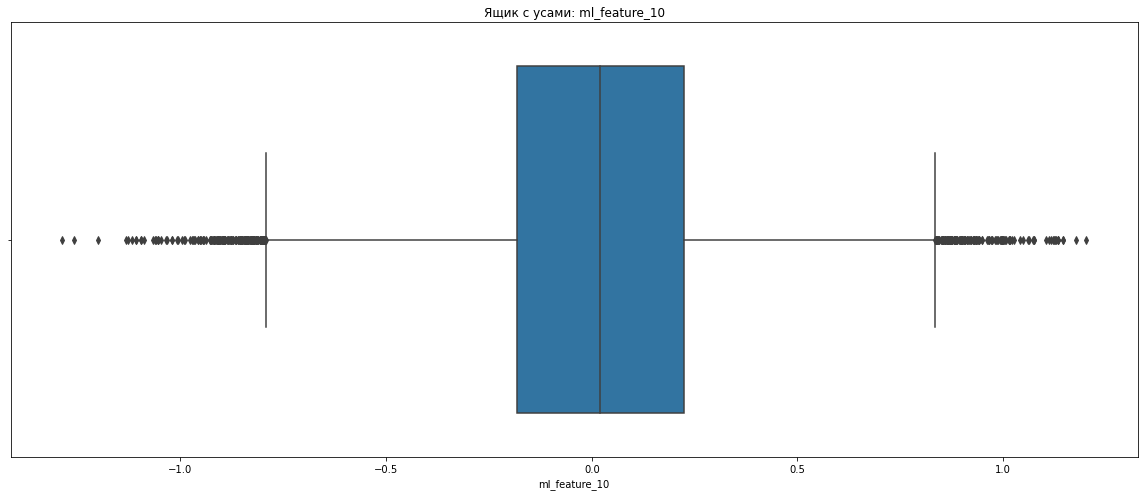

In [35]:
# Признаки с выбросами
plot_hist_box(df, ['ml_feature_1', 'ml_feature_5', 'ml_feature_9', 'ml_feature_10'])

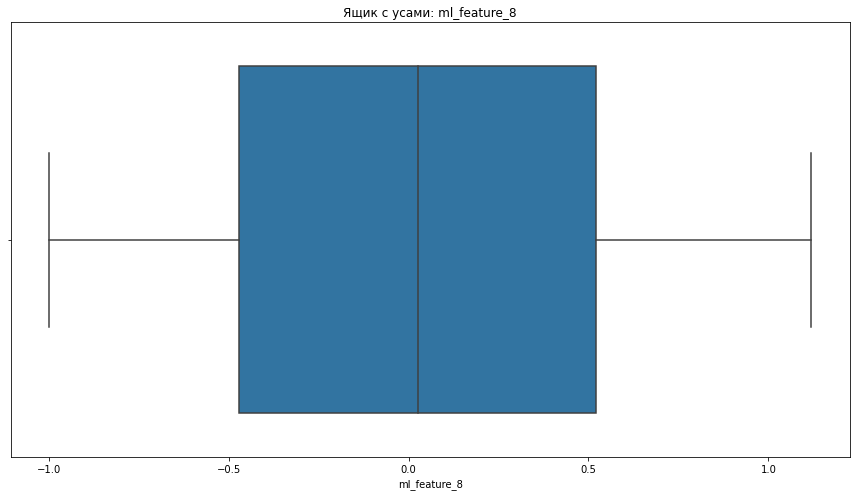

In [36]:
# Признаки с ограниченным диапазоном значений
plot_hist_box(df, ['ml_feature_3', 'ml_feature_6', 'ml_feature_8'])

Анализ выбросов и распределений проведён для семи непрерывных числовых признаков. По форме распределения неперрывные признаки деляться на две группы.
- Признаки `ml_feature_1`, `ml_feature_5`, `ml_feature_9`, `ml_feature_10` имеют нормальное распределение. Графики симметричны, среднее и медиана совпадают и близки к нулю, квартили расположены симметрично относительно центра. Различие только в разбросе значений. У `ml_feature_1` и `ml_feature_5` `str` около 1, у `ml_feature_9` - около 0.5, у `ml_feature_3` - 0.3. Порог в |3σ| определил в этих признаках от 130 до 146 выбросов, то есть где-то 0.26-0.29% строк, что имеет место в рамках нормального распределения. Выбросы за усами на диаграммах размаха расположены симметрично и вплотную примыкают к усам, отдельных далёких значений нет. Это естественные хвосты номрального распределения. 
- Признаки `ml_feature_3`, `ml_feature_6` и `ml_feature_8` имеют ограниченный диапазон значений. `ml_feature_3` распределён равномерно на отрезке [−10, 10]. `ml_feature_6` лежит строго в отрезке [−1, 1], значения сгущаются к краям, а в крайних интервалах у −1 и 1 наблюдаются резкие пики, что похоже на обрезку значений по границам отрезка. `ml_feature_8` распределён почти равномерно на отрезке примерно от −1 до 1, после чего идёт короткий хвост пониженной плотности до 1.12. Ни у одного из этих трёх признаков диаграмма размаха не показывает точек за усами.

Таким образом, явных ошибочных выбросов в числовых признаках нет. Значения в хвостах нормальных признаков и на границах ограниченных признаков отражают форму их распределений, поэтому удалять или заменять их не будем. Признаки различаются масштабом: от ±1 у `ml_feature_6` и `ml_feature_8` до ±10 у `ml_feature_3`. Это будет устранено масштабированием StandardScaler в пайплайне предобработки, что важно для логистической регрессии и SVM, чувствительных к масштабу признаков.

---

### 5.7 Корреляция

Большинство признаков категориальные, поэтому коэффициенты Пирсона, Спирмена и Кендалла здесь неприменимы. Используем коэффициент φk (`phik`): он работает с числовыми, категориальными и бинарными признаками и улавливает нелинейные зависимости. Признаки `device_model` (2521 категория) и `C14` (1497 категорий) в матрицу не включаем. У большинства их категорий слишком мало строк для надёжной оценки φk, а расчёт для них занимает основное время. Эти признаки остаются в модели, их связь с целевой переменной проверим в разделе отбора признаков после Target Encoding.

In [37]:
# Засекаем время
start = time()

# Расчёт матрицы корреляций
phik_corr = df.drop(columns=['device_model', 'C14']).phik_matrix().round(2)
print(f'Время расчёта: {time() - start:.0f} с')

interval columns not set, guessing: ['click', 'ml_feature_1', 'ml_feature_3', 'ml_feature_5', 'ml_feature_6', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10']
Время расчёта: 16 с


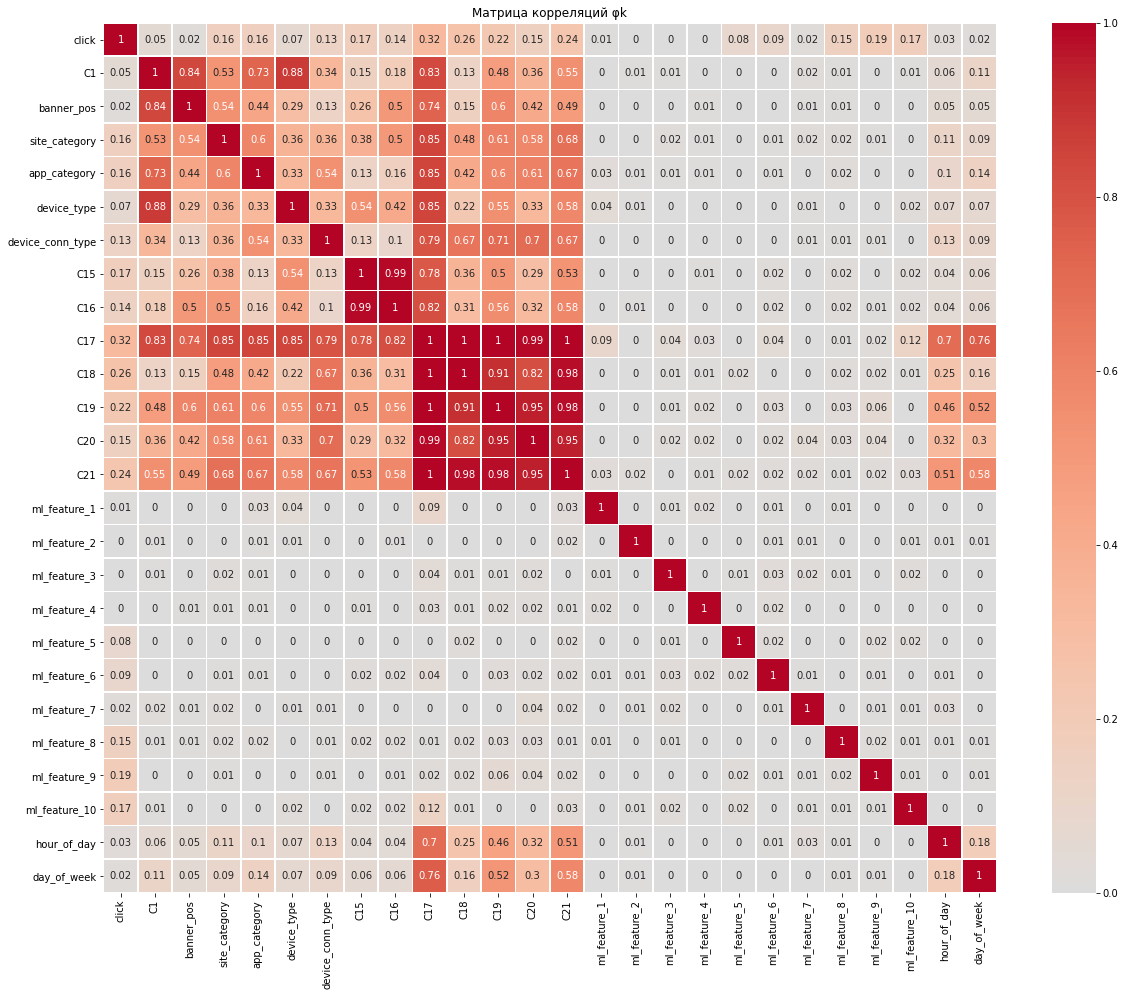

In [38]:
# Визуализация матрицы корреляции с помощью тепловой карты
plt.figure(figsize=(20, 16))
sns.heatmap(phik_corr, annot=True, cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Матрица корреляций φk')
plt.show()

In [39]:
# Корреляция признаков с целевой переменной
phik_corr['click'].drop('click').sort_values(ascending=False)

C17                 0.32
C18                 0.26
C21                 0.24
C19                 0.22
ml_feature_9        0.19
C15                 0.17
ml_feature_10       0.17
site_category       0.16
app_category        0.16
C20                 0.15
ml_feature_8        0.15
C16                 0.14
device_conn_type    0.13
ml_feature_6        0.09
ml_feature_5        0.08
device_type         0.07
C1                  0.05
hour_of_day         0.03
ml_feature_7        0.02
banner_pos          0.02
day_of_week         0.02
ml_feature_1        0.01
ml_feature_4        0.00
ml_feature_3        0.00
ml_feature_2        0.00
Name: click, dtype: float64

Матрица φk рассчитана для всех признаков, кроме `device_model` и `C14`, чьи оценки были бы ненадёжны из-за большого числа категорий.

Связь признаков с целевой переменной в целом слабая: 
- максимальное значение φk равно 0.32 (`C17`), ни один признак в отдельности не определяет клик. Наиболее связаны с `click` анонимизированные признаки `C17` (0.32), `C18` (0.26), `C21` (0.24) и `C19` (0.22). 
- практически не связаны с кликом `hour_of_day`, `day_of_week`, `banner_pos`, `ml_feature_7` и `ml_feature_1` (0.01–0.03), а у `ml_feature_2`, `ml_feature_3` и `ml_feature_4` значение равно нулю. 
- остальные признаки также демонстрируют слабую связь в разной степени (0.19 - 0.05)
- Время показа, выделенное из `hour`, по φk оказалось малоинформативным. 

Признаки с нулевой и близкой к нулю связью являются кандидатами на удаление при отборе признаков, где их полезность будет проверена на обучающей выборке.

Числовые признаки `ml_feature_1-10` практически не связаны ни между собой, ни с остальными признаками (φk не выше 0.12), поэтому мультиколлинеарности среди них нет.

Сильные взаимные связи обнаружены среди категориальных признаков:
- `C15` и `C16` почти дублируют друг друга (φk = 0.99), поэтому `C16`, который слабее связан с целевой переменной, стоит удалить. 
- `C17` связан с `C18`, `C19`, `C20` и `C21` на уровне 0.99–1.00, а эти признаки между собой связаны на уровне 0.82–0.98. Значение 1.0 между `C17` (387 категорий) и `C18` (4 категории) означает, что каждое значение `C17` однозначно задаёт значение `C18`, то есть признаки вложены друг в друга, и `C17` является более подробной группировкой. 

При этом φk для признака с сотнями категорий может быть завышен, поэтому удалять группу `C18`–`C21` только по этому критерию преждевременно. Решение о ней примем после кодирования на обучающей выборке. 

Также сильно связаны `C1` с `device_type` (0.88) и `banner_pos` (0.84). Эти пары оставляем, так как значения ниже порога 0.9, который мы считаем признаком дублирования.

<div class="alert alert-info"> 
<b>Примечание:</b> 

Связь `C14` и `C17` проверена в разделе 8.2 корреляцией Спирмена на `X_train_processed`: 0.853. Связь сильная, но не полная, поэтому оба признака оставлены, а осторожность в интерпретации их весов отражена в анализе весов модели.</div>

In [40]:
# Удаляем C16
df = df.drop(columns='C16')
cat_features.remove('C16')
ohe_features.remove('C16')

<div class="alert alert-info"> 
<b>Примечание:</b> 
    
Решение удалить `C16` принято по φk, посчитанному на всём датасете, то есть с учётом будущей тестовой выборки. Повторная проверка на обучающей выборке в разделе 8.2 подтвердила, что `C15` и `C16` почти дублируют друг друга (φk = 0.99), но показала, что `C16` связан с `click` сильнее (0.19 против 0.11 у `C15`). Замена `C15` на `C16` могла бы слегка улучшить качество.</div>

---

### 5.8 Выводы по EDA

**Общее.** Датасет содержит 50000 показов за 10 суток (21-30 октября 2014 года, все 240 часов без пропусков) и 34 столбца. Клик произошёл в 17.21% случаев показа - классы несбалансированы. Поэтому основной метрикой выбран PR-AUC, а доля кликов 0.172 задаёт уровень случайной модели, который наша модель должна превзойти.

**Пропуски.** Явных пропусков в данных нет. Признак `С20` хранит подозрительное значение `-1`, которое встречается в 46.9% строк и связано с повышенной долей кликов. Поэтому оно оставлено как отдельная категория и не считается пропуском.

**Разделение по категориям.** Из 23 числовых по `dtype` столбцов непрерывными являются только семь `ml_feature_*`, а целочисленные (`C1`, `banner_pos` `device_type`, `device_conn_type` и `C14-C21`) по смыслу являются кодами категорий.

**Выбросы.** Явных аномальных выбросов в числовых признаках нет. Выбросы по правилу 3σ у нормально распределённых признаков составляют 0.26-0.29% строк и соответствуют естестввенным хвостам распределения.

**Корреляционный анализ.** Связь отдельных признаков с целевой переменно `click` слабая. Максимальное значение φk равно 0.32. Среди категориальных признаков есть сильно связанные между собой: `C15` и `C16` практичесски дублируют друг друга (φk = 0.99), а `C17` почти полностью задаёт значения `C18`-`C21`.

Сильнее всего с целевой переменной `click` связаны анонимизированные признаки `C17` (0.32), `C18` (0.26), `C21` (0.24) и `C19` (0.22). За ними идут `ml_feature_9` (0.19), `C15` и `ml_feature_10` (0.17), категории площадки и приложения `site_category` и `app_category` (0.16), а также `C20` и `ml_feature_8` (0.15). Эти признаки выглядят наиболее перспективными, потому что именно они различают показы с разной вероятностью клика. 

Кандидатами на удаление являются признаки с нулевой или близкой к нулю связью: `ml_feature_2`, `ml_feature_3`, `ml_feature_4`, `ml_feature_1`, `ml_feature_7`, `banner_pos`, `hour_of_day` и `day_of_week`. Окончательное решение по ним, а также по группе `C18–C21`, примем в разделе отбора признаков на обучающей выборке. Для `C14` и `device_model` φk не рассчитывался из-за высокой кардинальности, их полезность будет проверена после Target Encoding.

На этапе EDA уже удалены служебный идентификатор `id`, практически уникальный `device_ip` и столбец `hour`, из которого выделены час суток и день недели. Удалены также идентификаторы площадок, приложений и устройств (`site_id`, `site_domain`, `app_id`, `app_domain`, `device_id`), так как модель должна обобщаться на новые сайты и приложения. Удалён `C16` как дубликат `C15`. В работу переходят 26 признаков: 7 числовых и 19 категориальных.

**Действия по предобработке.** Сначала данные нужно разделить на обучающую и тестовую выборки со стратификацией по `click`, так как всё, что обучается на данных, должно обучаться только на обучающей части. Затем предобработку собираем в пайплайн `ColumnTransformer` из трёх веток. Для числовых признаков пропуски заполняются медианой, потому что она устойчива к выбросам, после чего признаки масштабируются `StandardScaler`, это важно для логистической регрессии и SVM. Для 13 категориальных признаков с числом категорий не больше 24 пропуски заполняются отдельной категорией `missing`, после чего применяется `One-Hot Encoding` с `handle_unknown='ignore'`, чтобы новые категории не ломали модель. Для 6 признаков с высокой кардинальностью (`C21`, `C19`, `C20`, `C17`, `C14`, `device_model`) пропуски также заполняются категорией `missing`, после чего применяется `Target Encoding`. 

Обработка выбросов не требуется. Шаги заполнения пропусков добавляются в пайплайн, несмотря на их отсутствие в текущих данных, потому что пропуски могут появиться в новых данных.

---

## 6. Разделение данных на выборки

### 6.1 Разделение данных
Разделение выполняем в два шага по схеме train / calib / test. Сначала отделяем тестовую выборку (20% данных) со стратификацией по `click`. Она не участвует ни в обучении предобработки, ни в отборе признаков, ни в подборе гиперпараметров, ни в обучении калибратора и используется только для финальной оценки модели.

Оставшиеся 80% данных используются для обучения. Также выделяем калибровочную выборку, до отбора признаков и подбора гиперпараметров, чтобы её строки не участвовали ни в одном из этих этапов. Из обучающих 80% отделяем ещё 20% (8000 строк, 16% от всех данных) под калибровку, тоже со стратификацией.

Отдельную валидационную выборку не выделяем: подбор гиперпараметров и сравнение моделей будем проводить кросс-валидацией на 5 фолдах внутри обучающей выборки. В итоге получаем три независимые выборки: `train` (32000 строк) для обучения моделей и кросс-валидации, `calib` (8000) для обучения калибратора и `test` (10000) для финальной оценки.

In [41]:
# Признаки и целевая переменная
X = df.drop(columns='click')
y = df['click']

# Отделяем тестовую выборку (20% от всех данных)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Выделяем калибровочную выборку
X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

### 6.2 Проверка разделения
Убедимся, что распределение целевой переменной сохранено в каждой выборке. Также посмотрим на их размеры:

In [42]:
print(f'Обучающая (train): {len(X_train)}')
print(f'Калибровочная (calib): {len(X_calib)}')
print(f'Тестовая (test): {len(X_test)}')
print(f'Сумма: {len(X_train) + len(X_calib) + len(X_test)} из {len(X)}')

Обучающая (train): 32000
Калибровочная (calib): 8000
Тестовая (test): 10000
Сумма: 50000 из 50000


In [43]:
# Доля классов целевой переменной в каждой выборке
pd.DataFrame({
    'full': y.value_counts(normalize=True),
    'train': y_train.value_counts(normalize=True),
    'calib': y_calib.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True)
})

,full,train,calib,test
0,0.82794,0.827937,0.828,0.8279
1,0.17206,0.172063,0.172,0.1721


Расхождений в выборках практически нет, стратификация отработала как надо.

---

## 7. Предобработка данных — построение пайплайнов

### 7.1 Создание пайплайна для предобработки данных

Для **числовых признаков** (`num_features`) пайплайн состоит из двух шагов.
- Первый шаг, `SimpleImputer` с медианой, заполняет пропуски. В текущих данных их нет, но они могу появиться в новых. Медиана устойчива к выбросам, поэтому выбираем её.
- Второй шаг, `StandardScaler`, приводит признаки к нулевому среднему и единичному стандратному отклонению. Это важно при построении линейных моделей, таких как логистическая регрессия с регуляризацией и SVM, которые чувствительны к масштабу признаков.

Обработка выбросов не входит в пайплайн, это исправление самих данных, которое выполняют до пайплайна.

In [44]:
# Пайплайн для числовых признаков
numerical_pipeline = Pipeline(steps=[
    # Заполнение пропусков медианой
    ('imputer', SimpleImputer(strategy='median')),
    
    # Стандартизация
    ('scaler', StandardScaler())
])

numerical_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

**Категориальные** признаки обрабатываем двумя пайплайнами, по способоу кодирования.
- Первый шаг в обоих одинаковый: `SimpleImputer` с константой `missing` заполняет пропуски, так как отдельная категория лучше моды. Так показы без данных не смешаются с самой частой категорией и не исказят её долю кликов.
- Второй шаг пайплайна для признаков с малой кардинальностью (`ohe_features`): кодируем `OneHotEncoder`.
- Второй шаг пайплайна для признаков с высокой кардинальностью (`te_features`): кодируем `TargetEncoder`. Он стоит в `ColumnTransformer` без вложенного пайплайна, поэтому отдельный пайплайн с шагом заполнения пропусков для него не нужен (`TargetEncoder` по умолчанию сам кодирует пропуски и незнакомые категории средней долей кликов по обучающей выборке).

In [45]:
# Пайплайн для категориальных признаков с малой кардинальностью
ohe_pipeline = Pipeline(steps=[
    # Заполнение пропусков отдельной категорий
    ('inputer', SimpleImputer(strategy='constant', fill_value='missing')),
    
    # OHE
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

print(f'OHE ({len(ohe_features)}): {ohe_features}')
ohe_pipeline

OHE (13): ['ml_feature_4', 'ml_feature_7', 'device_type', 'device_conn_type', 'C18', 'ml_feature_2', 'C1', 'day_of_week', 'banner_pos', 'C15', 'site_category', 'app_category', 'hour_of_day']


Pipeline(steps=[('inputer',
                 SimpleImputer(fill_value='missing', strategy='constant')),
                ('onehot',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

In [46]:
# Ветка Target Encoding: кодирование + масштабирование
te_pipeline = Pipeline(steps=[
    ('te', TargetEncoder(target_type='binary', random_state=RANDOM_STATE)),
    ('scaler', StandardScaler())
])

print(f'TargetEncoder ({len(te_features)}): {te_features}')
te_pipeline

TargetEncoder (6): ['C21', 'C19', 'C20', 'C17', 'C14', 'device_model']


Pipeline(steps=[('te', TargetEncoder(random_state=49, target_type='binary')),
                ('scaler', StandardScaler())])

**Объединим пайплайны**
Объединим три ветки предобработки в один `ColumnTransformer`. Числовые признаки проходят через `numerical_pipeline`, категориальные с малой кардинальностью - через `ohe_pipeline`, а с высокой кардинальностью - через `te_pipeline`.

In [47]:
# Сборка препроцессора из трёх веток для заданных списков признаков
def make_preprocessor(num_cols, ohe_cols, te_cols):
    return ColumnTransformer(
        transformers=[
            ('num', numerical_pipeline, num_cols),
            ('ohe', ohe_pipeline, ohe_cols),
            ('te', te_pipeline, te_cols)
        ],
        remainder='drop'
    ).set_output(transform='pandas')

<div class="alert alert-info">

Неиспользуемый `preprocessor` убран. Вместо него описана функция `make_preprocessor`, которая собирает `ColumnTransformer` из трёх веток (числовые признаки, OHE, Target Encoding со `StandardScaler`) для заданных списков признаков. В разделе 8.2 `preprocessor_sel` теперь создаётся этой же функцией, так что остался один вариант препроцессора, а метрики в остальных разделах не изменились.
</div>

---

## 8. Отбор признаков

### 8.1 Применение фильтрационных методовКоэффициентов 
Коэффициентом `phik` на обучающей выборке считаем корреляцию с целевой переменной. Как и в EDA, `C14` и `device_model` в матрицу не включаем, так как у них слишком много категорий для надёжной оценки. Их надёжность проверим методом-обёрткой.

In [48]:
# Обучающая выборка вместе с целевой переменной
train_df = X_train.drop(columns=['C14', 'device_model']).copy()
train_df['click'] = y_train

# Корреляционная матрица phik
start = time()
phik_train = train_df.phik_matrix()
print(f'Время расчёта матрицы корреляций: {time() - start:.0f} с')

# Корреляция признаков с click
phik_target = round(phik_train['click'].drop('click').sort_values(ascending=False), 2)
phik_target

interval columns not set, guessing: ['ml_feature_1', 'ml_feature_3', 'ml_feature_5', 'ml_feature_6', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10', 'click']
Время расчёта матрицы корреляций: 14 с


C17                 0.32
C18                 0.26
C21                 0.24
C19                 0.21
ml_feature_9        0.19
ml_feature_10       0.17
ml_feature_8        0.16
C20                 0.16
site_category       0.16
app_category        0.15
device_conn_type    0.13
C15                 0.11
ml_feature_6        0.09
ml_feature_5        0.07
device_type         0.07
C1                  0.04
hour_of_day         0.04
ml_feature_7        0.02
banner_pos          0.02
day_of_week         0.02
ml_feature_4        0.01
ml_feature_2        0.01
ml_feature_3        0.00
ml_feature_1        0.00
Name: click, dtype: float64

In [49]:
# C15 и C16 с click на обучающей выборке (C16 берём из копии до удаления)
check_df = df_before_initial_selection.loc[X_train.index, ['C15', 'C16']].copy()
check_df['click'] = y_train

check_df.phik_matrix().round(2)

interval columns not set, guessing: ['click']


,C15,C16,click
C15,1.00,0.99,0.11
C16,0.99,1.00,0.19
click,0.11,0.19,1.00


Для наглядности построим тепловую карту

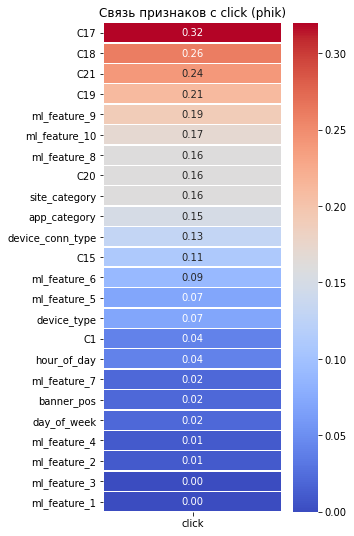

In [50]:
plt.figure(figsize=(4, 9))
sns.heatmap(phik_target.to_frame(), annot=True, fmt='.2f', cmap='coolwarm',
           linewidths=0.5)
plt.title('Связь признаков с click (phik)')
plt.show()

Значения `phik` на обучающей выборке почти совпадают с рассчитанными в `EDA` на полном датасете: у большинства признаков расхождение не больше 0.01, а порядок первых четырёх (`C17`, `C18`, `C21`, `C19`) не изменился. Это значит, что связь признаков с кликом устойчива и не зависит от конкретного разбиения. Заметно изменился только `C15`, его `phik` снизился с 0.17 до 0.11.

**Отберём топ лучших признаков.** Оставлять будем признаки с `phik >= 0.05`. Выше него стоят признаки со слабой, но заметной связью с кликом, 0.32 (`C17`) до 0.07 (`device_type`). Ниже идут признаки, у которых связи с `click` практически нет (< 0.05). Порог выбран визуально, к тому же, это самый крупный разрыв между значениями (`device_type` - `C1` = 0.03).

In [51]:
# Порог phik для отбора признаков
PHIK_THRESHOLD = 0.05

# Признаки, прошедшие отбор
filter_features = phik_target[phik_target >= PHIK_THRESHOLD].index.tolist()

# Признаки на удаление
dropped_by_phik = phik_target[phik_target < PHIK_THRESHOLD].index.tolist()

# Признаки высокой кардинальности оставляем для проверки обёрткой
filter_features += ['C14', 'device_model']

print(f'Отобрано признаков: {len(filter_features)}')
print(filter_features)
print(f'\nУдалено по phik: {dropped_by_phik}')

Отобрано признаков: 17
['C17', 'C18', 'C21', 'C19', 'ml_feature_9', 'ml_feature_10', 'ml_feature_8', 'C20', 'site_category', 'app_category', 'device_conn_type', 'C15', 'ml_feature_6', 'ml_feature_5', 'device_type', 'C14', 'device_model']

Удалено по phik: ['C1', 'hour_of_day', 'ml_feature_7', 'banner_pos', 'day_of_week', 'ml_feature_4', 'ml_feature_2', 'ml_feature_3', 'ml_feature_1']


Удалим признаки с очень низкой вариацией `VarianceThreshold`

In [52]:
data = X_train[filter_features]

# Отбираем числовые признаки
numerical_columns = data.select_dtypes(include=[np.number]).columns
numerical_data = data[numerical_columns]

print('Дисперсии числовых признаков:')
print(numerical_data.var().to_string(float_format='%.3f'))

# Обучаем VarianceThreshold
vs_constant = VarianceThreshold(threshold=0.0) 
vs_constant.fit(numerical_data)

# Находим константные числовые признаки
constant_num_columns = [col for col, keep in zip(numerical_columns, vs_constant.get_support()) if not keep]

# Отбор категориальных признаков с использованием select_dtypes()
constant_cat_columns = [col for col in data.select_dtypes(include=['object']).columns
                        if data[col].nunique() == 1]

# Объединяем все константные признаки
all_constant_columns = constant_num_columns + constant_cat_columns

print("\nКонстантные признаки для удаления (Variance = 0 или N_unique = 1):", all_constant_columns)

# Квази-константные категориальные признаки
quasi_cat_cols = [col for col in data.select_dtypes(include=['object']).columns
                  if data[col].value_counts(normalize=True).iloc[0] > 0.90]
print('Квази-константные категориальные признаки:', quasi_cat_cols)

Дисперсии числовых признаков:
ml_feature_9    0.256
ml_feature_10   0.092
ml_feature_8    0.334
ml_feature_6    0.431
ml_feature_5    1.002

Константные признаки для удаления (Variance = 0 или N_unique = 1): []
Квази-константные категориальные признаки: ['C15', 'device_type']


Константных признаков среди отобраных нет. У всех числовых признаков дисперсия больше нуля, а у категориальных больше одного знаечния. `C15` и `device_type` оказались квази-константными. Но они проходят по `phik`, поэтому оставляем их.

Итоговый набор после фильтрационных методов - 17 признаков: 15 прошли порог `phik`, и ещё `C14` и `device_model`, которые проверим методом-обёрткой.

---

### 8.2 Применение методов-обёртки

Методы-обёртки применяем к признакам, прошедшим фильтрацию.

Обёртки работают с закодированными столбцами, поэтому отбор идёт по отдельным категориям OHE-признаков, а не по исходным признакам целиком. Сравниваем два метода: прямой отбор (`SequentialFeatureSelector` из библиотеки `mlxtend`, импортирован как `SFS`) и рекурсивное исключение (`RFE` из `sklearn`). Обратный отбор не используем: он начинает с полного набора столбцов и на каждом шаге переобучает модель почти на всех из них, поэтому это самый затратный из методов-обёрток.

Прямой отбор запускается один раз на диапазон до 20 столбцов: путь до 10 столбцов полностью входит в него, поэтому лучший набор для каждого сценария (до 10 и до 20 столбцов) берётся из истории шагов селектора (`subsets_`). `RFE` оставляет ровно 10 или 20 столбцов.

In [53]:
# Разносим отобранные признаки по веткам предобработки
num_sel = [f for f in num_features if f in filter_features]
ohe_sel = [f for f in ohe_features if f in filter_features]
te_sel = [f for f in te_features if f in filter_features]

print(f'Числовые ({len(num_sel)}): {num_sel}')
print(f'OHE ({len(ohe_sel)}): {ohe_sel}')
print(f'Target Encoding ({len(te_sel)}): {te_sel}')

# Препроцессор только для отобранных признаков
preprocessor_sel = make_preprocessor(num_sel, ohe_sel, te_sel)

# Предварительный fit() для получения закодированных данных и имён столбцов
X_train_processed = preprocessor_sel.fit_transform(X_train, y_train)
feature_names = preprocessor_sel.get_feature_names_out()

# Массив NumPy для отбора
X_train_np = X_train_processed.to_numpy()

print(f'\nСтолбцов после кодирования: {len(feature_names)}')

Числовые (5): ['ml_feature_5', 'ml_feature_6', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10']
OHE (6): ['device_type', 'device_conn_type', 'C18', 'C15', 'site_category', 'app_category']
Target Encoding (6): ['C21', 'C19', 'C20', 'C17', 'C14', 'device_model']

Столбцов после кодирования: 66


In [54]:
# Проверка пары C14 и C17: после кодирования считаем корреляцию Спирмена между столбцами,
# так как C14 не вошёл в матрицу φk из-за высокой кардинальности
X_train_processed[['te__C14', 'te__C17']].corr(method='spearman')

,te__C14,te__C17
te__C14,1.000000,0.853081
te__C17,0.853081,1.000000


<div class="alert alert-info"> 

Корреляция Спирмена между закодированными `C14` и `C17` равна 0.853: связь сильная, но не полная, поэтому признаки частично делят один сигнал и всё же несут разную информацию. Оба остаются в финальном наборе, потому что отбор по `PR-AUC` их не отверг (`C14` и `C17` вошли в набор прямого отбора уже на 10 столбцах). Из-за общей части сигнала веса `te__C14` и `te__C17` по отдельности нужно интерпретировать осторожно, это учтём в анализе весов модели.

</div>

In [55]:
%%writefile ctr_utils.py
def select_columns(X, columns):
    # Оставляет столбцы по именам; отсутствующие в фолде категории OHE заполняет нулями
    return X.reindex(columns=columns, fill_value=0)

Overwriting ctr_utils.py


In [56]:
from ctr_utils import select_columns

# Модель для отбора и оценки
lr_estimator = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

# Кросс-валидация внутри отбора (3 фолда) и для итоговой оценки (5 фолдов)
cv_select = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_eval = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Метрика
scoring_metric = 'average_precision'


def wrapper_selection(method_name, estimator, X, y, k=(1, 20), forward=True, rfe_k=None):
    # Запускает RFE или SFS и возвращает обученный селектор и время работы
    print(f'\nЗапуск: {method_name}, forward={forward}, k={k if method_name != "RFE" else rfe_k}')
    start_time = time()
    if method_name == 'RFE':
        selector = RFE(estimator, n_features_to_select=rfe_k, verbose=1)
    else:
        selector = SFS(estimator, k_features=k, forward=forward,
                       scoring=scoring_metric, cv=cv_select, n_jobs=-1, verbose=2)
    selector.fit(X, y)
    elapsed = time() - start_time
    return selector, elapsed

def sfs_best_features(selector, feature_names, k_max):
    #Лучший по метрике набор SFS размером не больше k_max
    best_size = max((size for size in selector.subsets_ if size <= k_max),
                    key=lambda size: selector.subsets_[size]['avg_score'])
    return np.array(feature_names)[list(selector.subsets_[best_size]['feature_idx'])]

def build_pipeline(selected_features):
    # Пайплайн: предобработка -> выбор столбцов -> модель; оценка PR-AUC на 5 фолдах
    selector = FunctionTransformer(select_columns, kw_args={'columns': list(selected_features)})

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_sel),
        ('selector', selector),
        ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])

    score = cross_val_score(pipeline, X_train, y_train, scoring=scoring_metric,
                            cv=cv_eval, n_jobs=-1).mean()
    return pipeline, score

Запуск отбора

In [ ]:
results = []
selected_sets = {}

# Точка отсчёта: все столбцы без отбора
_, base_score = build_pipeline(feature_names)
results.append({'k': len(feature_names), 'Метод': 'Без отбора',
                'Признаков': len(feature_names), 'Время, с': 0.0,
                'PR-AUC (CV)': base_score})

start = time()

# Прямой отбор. Один запуск на диапазон до 20 столбцов
forward_sfs, forward_time = wrapper_selection(
    'SFS', lr_estimator, X_train_np, y_train, k=(1, 20), forward=True)

for k_max in [10, 20]:
    rfe_selector, rfe_time = wrapper_selection(
        'RFE', lr_estimator, X_train_np, y_train, rfe_k=k_max)

    candidates = [
        ('Forward Selection', sfs_best_features(forward_sfs, feature_names, k_max), forward_time),
        ('RFE', np.array(feature_names)[rfe_selector.support_], rfe_time)
    ]

    for method_name, features, elapsed in candidates:
        _, score = build_pipeline(features)
        selected_sets[(method_name, k_max)] = features
        results.append({'k': k_max, 'Метод': method_name, 'Признаков': len(features),
                        'Время, с': elapsed, 'PR-AUC (CV)': score})
        print(f'{method_name}, k={k_max}: PR-AUC = {score:.4f}')
        
print(f'Отбор занял {time() - start:.2f} секунд')


Запуск: SFS, forward=True, k=(1, 20)


[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:   40.6s
[Parallel(n_jobs=-1)]: Done  66 out of  66 | elapsed:  1.1min finished

[2026-10-30 09:44:00] Features: 1/20 -- score: 0.2924857618687457[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:   47.3s
[Parallel(n_jobs=-1)]: Done  65 out of  65 | elapsed:  1.3min finished

[2026-10-30 09:45:17] Features: 2/20 -- score: 0.32964110120986984[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:   54.4s
[Parallel(n_jobs=-1)]: Done  64 out of  64 | elapsed:  1.4min finished

[2026-10-30 09:46:41] Features: 3/20 -- score: 0.35558751483912426[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:   51.8s
[Parallel(n_jobs=-1)]: Done  63 out of  63 | elapsed:  1.4min finished

[2026-10-30 09:48:06] Features: 4/20 -- score: 0.3654267922832406[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done  62 out of  62 | elapsed:  1.5min finished

[2026-10-30 09:49:39] Features: 5/20 -- score: 0.3718843084625007[Pa

Сводная таблица и списки столбцов

In [ ]:
results_df = pd.DataFrame(results)
print('=== Сводная таблица результатов ===')
print(results_df.to_string(index=False, float_format='%.4f'))

best = results_df.sort_values('PR-AUC (CV)', ascending=False).iloc[0]
print(f"\nЛучшая стратегия: {best['Метод']}, k={best['k']}, PR-AUC = {best['PR-AUC (CV)']:.4f}")

for (method_name, k), features in selected_sets.items():
    print(f'\n{method_name}, k={k}:')
    print('  • ' + '\n  • '.join(features))

**Выводы по методам-обёртки**

Модель на всех 66 закодированных столбцах показала `PR_AUC` 0.3893 на 5-фолдовой кросс-валидации. Это заметно выше уровня случайной модели (0.172).

Прямой отбор на 20 столбцах дал ту же `PR AUC` (0.3893), тоо есть сохранил качество полной модели при втрое меньшем числе столбцов Набор из 10 столбцов уступает ему всего на 0.005 (0.3845). По истории шагов видно, что метрика быстро растт на первых пяти столбцах, затем рост замедляется, и после 10 столбцов прибавка на каждом шаге не превышает 0.001. Основная часть информации сосредоточена в небольшом наборе признаков. 

В оба набора прямого отбора вошли все пять числовых признаков (`ml_feature_5, 6, 8, 9, 10`) и три признака после `Target Encoding`: `C17`, `C14` и `device_model`. Тем самым подтверждена полезность `C14` и `device_model`, которые фильтрационный метод оценить не смог из-за высокой кардинальности.

`RFE` в исходном виде показал значительно худший результат: `PR-AUC` 0.2948 на 10 столбцах и 0.2965 на 20, почти на 0.1 ниже полной модели. Его набор состоял в основном из отдельных категорий `site_category` и `app_category`, а все числовые признаки были исключены.

---

### 8.3 Отбор финального набора признаков

Объединим результаты фильтрации и методов-обёрток. Сначала сведём в одну таблицу, какие закодированные столбцы выбрал каждый из четырёх наборов (прямой отбор и `RFE` на 10 и 20 столбцов), и найдём столбцы, выбранные всеми методами сразу. Затем выберем финальный набор по метрике `PR-AUC` на кросс-валидации и проверим, какие исходные признаки из прошедших фильтрацию в него вошли, а какие отсеялись на этапе обёрток.

In [ ]:
# Сколько столбцов каждого исходного признака выбрал каждый метод
comparison = pd.DataFrame(index=filter_features)

for (method_name, k), features in selected_sets.items():
    comparison[f'{method_name}, k={k}'] = [
        sum(col in (f'num__{f}', f'te__{f}') or col.startswith(f'ohe__{f}_') for col in features)
        for f in filter_features
    ]

# Сумма по всем методам
comparison['Всего'] = comparison.sum(axis=1)

comparison.sort_values('Всего', ascending=False)

Сравнение наборов показывает, что признак `C17` выбрали все четыре метода. Это согласуется с фильтрацией, где у него наибольшая связь с кликом (`phik` = 0.32). Прямой отбор и `RFE` выбирают  разные признаки. Оба набора прямого отбора включают все пять числовых признаков и признаки после `Target Encoding` (`C17`, `C14`, `device_model`, а при `k=20` ещё `C20` и `C21`). `RFE` почти целиком состоит из отдельных категорий `site_category` и `app_category`. Вероятная причина в том, что `RFE` отбрасывает столбцы с наименьшими по модулю коэффициентами, а немасштабированные OHE-столбцы редких категорий получают большие коэффициенты. Такой набор даёт `PR-AUC` около 0.295 против 0.389 у прямого отбора. Признак `C19` не выбрал ни один метод. Его информацию, по-видимому, уже содержит `C17`, с которым в `EDA` была почти полная связь (`phik` 0.99–1.00).

**Выбор финального набора признаков**

In [ ]:
# Финальный набор: прямой отбор, k=20
final_features = list(selected_sets[('Forward Selection', 20)])

# Исходные признаки, из которых состоит набор
final_source_features = comparison[comparison['Forward Selection, k=20'] > 0].index.tolist()

print(f'Столбцов после кодирования: {len(final_features)}')
print(f'Исходных признаков ({len(final_source_features)}): {final_source_features}')

# Проверка: PR-AUC финального набора на 5 фолдах
final_selection_pipeline, final_score = build_pipeline(final_features)
print(f'PR-AUC (CV): {final_score:.4f}')

В качестве финального выбран набор прямого отбора из 20 закодированных столбцов. Он сохраняет качество модели на всех 66 столбцах (`PR-AUC` 0.3893 на 5-фолдовой кросс-валидации) при втрое меньшем числе столбцов. Набор из 10 столбцов уступает ему на 0.005, а наборы `RFE` теряют около 0.09, поэтому они не подходят.

<div class="alert alert-info">
    
Оценка 0.3893 слегка оптимистична: набор выбирался по кросс-валидации на `X_train`, и ту же кросс-валидацию мы использовали для его проверки, поэтому часть результата может объясняться подгонкой под конкретные фолды. Честнее было бы вложенной кросс-валидацией, но она потребовала бы многократного запуска прямого отбора, который и так занял около часа. Независимую проверку даёт тестовая выборка в разделе 11.2. 
</div>

Финальный набор состоит из 16 исходных признаков, и все они прошли фильтрацию. Это пять числовых признаков (`ml_feature_5, 6, 8, 9, 10`), пять признаков после `Target Encoding` `(C17`, `C20`, `C21`, `C14`, `device_model`) и отдельные категории шести OHE-признаков (`site_category`, `app_category`, `device_conn_type`, `device_type`, `C15`, `C18`). Из признаков, прошедших фильтрацию, не вошёл только `C19`.

---

## 9. Обучение базовой модели
Нужно обозначить самый простой базовый уровень работы модели. Обучим `DummyClassifier` со стратегией `most_frequent`. Он не использует признаки и всегда предсказывает самый частый класс, то есть "клика нет". Это самый простой базовый уровень, который должны превзойти настоящие модели.

### 9.1 Обучение `DummyClassifier`

In [ ]:
# Инициализация DummyClassifier
baseline = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)

# Запускаем кросс-валидацию на 5 фолдах
res = cross_validate(baseline, X_train, y_train,
                    scoring=['accuracy', 'average_precision', 'f1'], cv=cv_eval)

# Метрики по фолдам
print('Accuracy:', np.round(res['test_accuracy'], 3))
print('PR-AUC:', np.round(res['test_average_precision'], 3))
print('F1:', np.round(res['test_f1'], 3))

# Средние значения по фолдам
dummy_results_mean = {
    'accuracy': np.mean(res['test_accuracy']).round(3),
    'pr_auc': np.mean(res['test_average_precision']).round(3),
    'f1': np.mean(res['test_f1']).round(3)
}

print('\nСредние значения:')
print(dummy_results_mean)

Базовая модель `DummyClassifier` всегда предсказывает самый частый класс "клика нет" и не использует признаки. На кросс-валидациииз 5 фолдов её `Accuracy` составила 0.828 - это доля показов без клика. Модель кажется точной, хотя не нашла ни одного клика. Поэтому `Accuracy` при дисбалансе классов неинформативен. `F1` равен 0, так как модель не предсказала ни одного положительного объекта. `PR AUC` составила 0.172, что совпадает с долей кликов в выборке - соответствует уровню случайной модели. Модель не зависит от данных, поэтому значения метрик одинаковы на всех фолдах. Полученный `PR-AUC` принимаем за минимальный уровень. Обучаемые модели должны его превзойти.

---

### 9.2 Обучение `LogisticRegression`
Обучим логитическую регрессию на финальном наборе признаков. Предобработк, выбор отобранных столбцов и модель объеденены в один пайплайн, поэтому при кросс-валидации кодирование и масштабирование на каждом фолде обучаются только на обучающей выборке, чтоы не было утечки данных. Оценка выполняется на тех же 5 фолдах, что и для `DummyClassifier`. Считаем основную метрику `PR-AUC`. `Log Loss` использем для оценки точности вероятностей, а также `Precison`, `Recall` и `F1` при пороге 0.5.

In [ ]:
# Пайплай
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_sel),
    ('selector', FunctionTransformer(select_columns, kw_args={'columns': final_features})),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

# Кросс-валидация на 5 фолдах
res_lr = cross_validate(lr_pipeline, X_train, y_train,
                       scoring=['average_precision', 'neg_log_loss', 'precision', 'recall', 'f1'],
                       cv=cv_eval, n_jobs=-1)

# Метрики по фолдам
print('PR-AUC:', np.round(res_lr['test_average_precision'], 3))
print('Log Loss:', np.round(-res_lr['test_neg_log_loss'], 3))
print('Precision:', np.round(res_lr['test_precision'], 3))
print('Recall:', np.round(res_lr['test_recall'], 3))
print('F1:', np.round(res_lr['test_f1'], 3))

# Среднее значение по фолдам
lr_results_mean = {
    'pr_auc': np.mean(res_lr['test_average_precision']).round(3),
    'log_loss': np.mean(-res_lr['test_neg_log_loss']).round(3),
    'precision': np.mean(res_lr['test_precision']).round(3),
    'recall': np.mean(res_lr['test_recall']).round(3),
    'f1': np.mean(res_lr['test_f1']).round(3)
}

print('\nСредние значения:')
print(lr_results_mean)

Логистическая регрессия на финальном наборе признаков показала на кросс-валидации из 5 фолдов средний `PR-AUC` 0.389. Это в 2.3 раза выше уровня `DummyClassifier` (0.172). Модель научилась отделять показы с кликом от показов без него. Значения `PR-AUC` по фолдам лежат в диапазоне от 0.370 до 0.407, так что качество стабильно и не зависит от конкретного разбиения. 

Средний `Log Loss` составил 0.403. Это точка отсчёта для оценки вероятностей при подборе гиперпараметров и калибровке.

Метрики при пороге 0.5 показывают, что модель редко выдаёт вероятность клика выше 0.5. Если предсказывает клик, то в 62% случаев не ошибается (`Presision = 0.618`), но находит лишь около 10% всех кликов (`Recall = 0.102`), поэтому и `F1` невысокий. 

---

### 9.3 Обучение `SVC`
Обучим `SVC` с линейным ядром на финальном наборе признаков. Пайплайн тот же, что у логистической регрессии: предобработка, выбор отобранных столбцов и модель. Модель задаём с `probability=False`, калибровку проведём позже.

In [ ]:
# Пайплай
svc_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_sel),
    ('selector', FunctionTransformer(select_columns, kw_args={'columns': final_features})),
    ('model', SVC(kernel='linear', probability=False, random_state=RANDOM_STATE))
])

# Кросс-валидация на 5 фолдах
start = time()
res_svc = cross_validate(svc_pipeline, X_train, y_train,
                       scoring=['average_precision', 'precision', 'recall', 'f1'],
                       cv=cv_eval, n_jobs=-1)
print(f'Время кросс-валидации: {time() - start:.0f} с\n')

# Метрики по фолдам
print('PR-AUC:', np.round(res_svc['test_average_precision'], 3))
print('Precision:', np.round(res_svc['test_precision'], 3))
print('Recall:', np.round(res_svc['test_recall'], 3))
print('F1:', np.round(res_svc['test_f1'], 3))

# Среднее значение по фолдам
svc_results_mean = {
    'pr_auc': np.mean(res_svc['test_average_precision']).round(3),
    'precision': np.mean(res_svc['test_precision']).round(3),
    'recall': np.mean(res_svc['test_recall']).round(3),
    'f1': np.mean(res_svc['test_f1']).round(3)
}

print('\nСредние значения:')
print(svc_results_mean)

`SVC` с линейным ядром на кросс-валидации из 5 фолдов показал средний `PR-AUC` 0.275. Это выше уровня `DummyClassifier` (0.172), то есть модель частично отделяет показы с кликом от показов без них, но заметно хуже логистической регрессии (0.389). К тому же качество менее стабильно: `PR-AUC` по фолдам меняется от 0.222 до 0.311.

`Precision`, `Recall` и `F1` на всех фолдах равны нулю.
<div class="alert alert-info">
    
Модель не предсказывает ни одного клика. SVC относит объект к классу "клик" только при положительном значении `decision_function`, а при дисбалансе классов (клики составляют 17%) граница сдвигается в сторону частого класса "клика нет", и на всех фолдах значения оказываются отрицательными. PR-AUC при этом остаётся ненулевым (0.275), потому что он оценивает только порядок объектов по `decision_function`, а не конкретную метку. Значит, SVC ранжирует показы лучше случайного, но с порогом по умолчанию клики не находит.
    
</div>

Более слабое ранжирование объясняется устройством модели. Логистическая регрессия минимизирует `log-loss` и учитывает все объекты, а `SVC` минимизирует `hinge loss` и ориентируется в основном на опорные векторы у границы, поэтому порядок остальных объектов для неё менее важен. Влияние параметра регуляризации `C` на качество `SVC` проверим при подборе гиперпараметров. `Log Loss` для `SVC` посчитаем в разделе калибровки после перевода `decision_function` в вероятности сигмоидой.

---

### 9.4 Сравнение моделей
Сведём средние метрики кросс-валидации трёх моделей в одну таблицу. Все модели оцнивались на одних и тех же 5 фолдах обучающей выборки, поэтому их метрики можно сравнивать напрямую. 

In [ ]:
# Сводная таблица метрик кросс-валидации
models_cv = pd.DataFrame(
    [dummy_results_mean, lr_results_mean, svc_results_mean],
    index=['DummyClassifier', 'LogisticRegression', 'SVC']
)[['pr_auc', 'log_loss', 'precision', 'recall', 'f1']]

models_cv

Логистическая регрессия работает лучше `DummyClassifier`, её `PR-AUC` равен 0.389 против 0.172, то есть в 2.3 раза выше уровня случайной модели. В отличие от базоваой модели, она находит часть кликов: `Precision` 0.618 и `Recall` 0.102 при пороге 0.5, когда `DummyClassifier` не предсказывает ни одного клика (`F1 = 0`).

Логистическая регрессия также превосходит `SVC` с линейным ядром. `PR-AUC` выше на 0.14, а качество по фолдам стабильнее. К тому же логистическая регрессия сразу выдаёт вероятности.

---

## 10. Подбор гиперпараметров: `Grid Search` с кросс-валидацией
### 10.1 Определение сетки гиперпараметров
Определим ключевые параметры, которые влияют на качество моделей `LogisticRegression` и `SVC`.

In [ ]:
# Сетка гиперпараметров для логистической регрессии
lr_param_grid = {
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'model__penalty': ['l1', 'l2'],
    'model__solver': ['liblinear']
}

# Сетка гиперпараметров для SVC с линейным ядром
svc_param_grid = {
    'model__C': [0.001, 0.01, 0.1, 1]
}

# Число обучений
n_lr = len(lr_param_grid['model__C']) * len(lr_param_grid['model__penalty'])
n_svc = len(svc_param_grid['model__C'])
print(f'LogisticRegression: {n_lr} комбинаций, {n_lr * 5} обучений')
print(f'SVC: {n_svc} комбинаций, {n_svc * 5} обучений')

---

### 10.2 Применение `Grid Search`

In [ ]:
def run_grid_search(pipeline, param_grid, scoring):
    # Подбор гиперпараметров по PR-AUC и вывод мметрик лучшей конфигурации
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv_eval,
        scoring=scoring,
        refit='average_precision',
        n_jobs=-1,
        verbose=1
    )
    
    start = time()
    grid.fit(X_train, y_train)
    print(f'Время поиска: {time() - start:.0f} с')
    
    best_idx = grid.best_index_
    print('Лучшие гиперпараметры:', grid.best_params_)
    print(f'PR-AUC: {grid.best_score_:.3f} '
         f'(std {grid.cv_results_["std_test_average_precision"][best_idx]:.3f})')
    
    # Log Loss, если он считался (знак инвертируем)
    if 'neg_log_loss' in scoring:
        print(f'Log Loss: {-grid.cv_results_["mean_test_neg_log_loss"][best_idx]:.3f}')
        
    return grid

In [ ]:
# Логистическая регрессия
lr_grid = run_grid_search(
    lr_pipeline, lr_param_grid,
    scoring={'average_precision': 'average_precision', 'neg_log_loss': 'neg_log_loss'}
)

In [ ]:
# SVC
svc_grid = run_grid_search(
    svc_pipeline, svc_param_grid,
    scoring={'average_precision': 'average_precision'}
)
svc_grid

Подбор гиперпараметров практически не изменил качество моделей. Лучшей конфигурацией логистической регрессии оказалась модель со слабой L1-регуляризацией (C=100, penalty='l1'). Её PR-AUC на кросс-валидации равен 0.390 против 0.389 у модели с параметрами по умолчанию, а Log Loss не изменился (0.403). Разница 0.001 в несколько раз меньше стандартного отклонения по фолдам (0.012), то есть лежит в пределах шума.

---

### Таблица результатов

In [ ]:
# Концигурации логистической регрессии
lr_results = pd.DataFrame(lr_grid.cv_results_)
lr_results['model'] = 'LogisticRegression'
lr_results['log_loss'] = -lr_results['mean_test_neg_log_loss']    # знак инвертируем

In [ ]:
# Конфигурации SVC (в сетке всего 4)
svc_results = pd.DataFrame(svc_grid.cv_results_)
svc_results['model'] = 'SVC'    # Log Loss для SVC не считался, будет NaN

In [ ]:
# Общая таблица
all_results = pd.concat([lr_results, svc_results], ignore_index=True)
all_results_table = all_results[['model', 'params', 'mean_test_average_precision',
             'std_test_average_precision', 'log_loss']] \
    .sort_values('mean_test_average_precision', ascending=False)

# Топ-10 конфигураций обеих моделей
all_results_table.head(10)

In [ ]:
# Все конфигурации обеих моделей
all_results_table

Таблица лучших конфигураций логистической регрессии показывает, что при `C` от 1 до 100 качество модели практически не зависит от гиперпараметров. Шесть верхних конфигураций с `L1-` и `L2`-регуляризацией дают `PR-AUC` от 0.3894 до 0.3896 и `Log Loss` около 0.403. Различия между ними в десятки раз меньше стандартного отклонения по фолдам (около 0.012). Метрика постепенно выравнивается, поэтому расширение сетки в сторону больших `C` не дало бы прироста. Заметное снижение качества наблюдается только при сильной регуляризации: при `C=0.01` `PR-AUC` падает до 0.382-0.385, а конфигурации с `C=0.001` не вошли в десятку лучших. Вид регуляризации почти не влияет на результат: при одинаковом `C` модели с `L1` и `L2` имеют практически одинаковые метрики. Для `SVC` с линейным ядром лучшим оказалось значение `C=1` с `PR-AUC` 0.275. При более сильной регуляризации (`C` от 0.001 до 0.1) `PR-AUC` снижается до 0.247-0.255, а стандартное отклонение по фолдам возрастает почти вдвое, до 0.055-0.060, то есть модель становится не только хуже, но и менее стабильной. Даже лучшая конфигурация `SVC` уступает логистической регрессии примерно 0.115 по `PR-AUC`. Поэтому логистическая регрессия остаётся основной моделью, а гиперпараметры для финальных моделей берём из лучших конфигураций `Grid Search`.

---

## 11. Финальная модель
### 11.1 Обучение финальной модели
В качестве финальных моделей берём лучшие пайплайны из `Grid Search` (`best_estimator_`). Обучать их заново не нужно, так как поиск запускался с параметром `refit='average_precision'`, поэтому после перебора `GridSearchCV` уже переобучил каждый пайплайн с лучшими гиперпараметрами на всей обучающей выборке `X_train`. Выведем подобранные параметры и убедимся, что модели обучены на нужном объёме данных.

In [ ]:
# Финальные модели
lr_final = lr_grid.best_estimator_
svc_final = svc_grid.best_estimator_

print('LogisticRegression:', lr_grid.best_params_)
print(lr_final.named_steps['model'])

print('\nSVC:', svc_grid.best_params_)
print(svc_final.named_steps['model'])

print(f'\nРазмер обучающей выборки: {len(X_train)}')

Финальные модели обучены на всей обучающей выборке `X_train` (32000 строк). Калибровочная и тестовая выборки в обучении не участвовали. Финальная логистическая регрессия обучена с `C=100` и `L1`-регуляризацией, то есть с очень слабой регуляризацией. Финальный `SVC` с линейным ядром обучен с `C=1`. Основной моделью остаётся логистическая регрессия, а `SVC` используем для сравнения калибровки двух моделей.

---

### 11.2 Подсчёт метрики на тестовой выборке
Оценим финальные модели на тестовой выборке, которая до этого момента не участвовала ни в обучении, ни в отборе признаков, ни в подборе гиперпараметров. Для логистической регрессии вероятность клика получаем методом predict_proba. SVC обучен с probability=False и выдаёт только значения решающей функции, поэтому переводим их в диапазон [0, 1] стандартной необученной сигмоидой. Это не калибровка, а только приведение к шкале вероятностей, чтобы можно было посчитать оценку Бриера и Log Loss. Основная метрика — PR-AUC, она оценивает качество ранжирования показов. Оценка Бриера и Log Loss показывают, насколько точны сами вероятности.

In [ ]:
# Стандартная сигмоида для перевода decision_function SVC в [0, 1]
def sigmoid_numpy(x):
    return 1 / (1 + np.exp(-x))

# Вероятности клика на тестовой выборке
lr_test_proba = lr_final.predict_proba(X_test)[:, 1]
svc_test_proba = sigmoid_numpy(svc_final.decision_function(X_test))

# Метрики на тестовой выборке
test_results = pd.DataFrame({
    'pr_auc': [average_precision_score(y_test, lr_test_proba),
               average_precision_score(y_test, svc_test_proba)],
    'brier': [brier_score_loss(y_test, lr_test_proba),
              brier_score_loss(y_test, svc_test_proba)],
    'log_loss': [log_loss(y_test, lr_test_proba),
                 log_loss(y_test, svc_test_proba)]
}, index=['LogisticRegression', 'SVC']).round(3)

print(f'Доля кликов в тестовой выборке: {y_test.mean():.3f}')
test_results

In [ ]:
# Метки классов при пороге 0.5
test_preds = {
    'LogisticRegression': (lr_test_proba >= 0.5).astype(int),
    'SVC': (svc_test_proba >= 0.5).astype(int)
}

# Precision, Recall и F1 на тестовой выборке
pd.DataFrame({
    name: {
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred)
    }
    for name, pred in test_preds.items()
}).T.round(3)

На тестовой выборке логистическая регрессия показала PR-AUC 0.384. Это в 2.2 раза выше уровня случайной модели, равного доле кликов в тесте (0.172). Значение близко к результату кросс-валидации (0.390) и отличается от него меньше, чем на одно стандартное отклонение по фолдам (0.012). Log Loss на тесте (0.404) практически совпадает с кросс-валидацией (0.403). Значит, модель не переобучилась и одинаково работает на обучающих и новых данных.

При пороге 0.5 метрики логистической регрессии на тесте тоже близки к кросс-валидации: `Recall` 0.103 и `F1` 0.175 совпадают, `Precision` 0.58 против 0.618, и эта разница лежит в пределах разброса по фолдам (от 0.565 до 0.646). Модель находит только около 10% кликов, поэтому для задачи важнее порядок показов и точность вероятностей (PR-AUC и оценка Бриера), чем метки при пороге. У SVC Precision, Recall и F1 на тесте равны нулю, как и на кросс-валидации: у всех показов значение decision_function отрицательно, и модель не предсказывает ни одного клика.

PR-AUC у SVC с линейным ядром на тесте показал 0.324, это выше результата кросс-валидации (0.275). Разрыв больше стандартного отклонения по фолдам (0.032). На кросс-валидации SVC обучался на строках каждого разбиения, а финальная модель обучена на всей обучающей выборке, а результат SVC сильно зависит от разбиения (по фолдам PR-AUC колеблется от 0.222 до 0.311). Поэтому тестовое значение лежит чуть выше диапазона, который показали фолды. Всё равно SVC уступает логистической регрессии в ранжировании показов (0.324 против 0.384), хотя разрыв оказался меньше, чем на кросс-валидации.

Оценка Бриера показывает, насколько предсказанная вероятность в среднем отличается от того, что произошло на самом деле: чем она меньше, тем точнее вероятности. У логистической регрессии она равна 0.126, у SVC 0.152. Log Loss ведёт себя так же: 0.404 у логистической регрессии и 0.485 у SVC. Значит, вероятности логистической регрессии заметно точнее. Причина в устройстве моделей. Логистическая регрессия при обучении сразу подбирает вероятности клика. SVC учится только разделять классы и вероятностей не выдаёт, поэтому мы перевели его оценки в диапазон от 0 до 1 простой сигмоидой, которая никак не обучалась на данных. Такие числа похожи на вероятности, но не обязаны совпадать с реальной частотой кликов. Чтобы проверить, насколько вероятности обеих моделей соответствуют реальности, и исправить их, в далее нужно будет провести калибровку. 

### 11.3 Анализ весов модели

In [ ]:
# Получаем веса из обученной модели
weights = lr_final.named_steps['model'].coef_[0]

# Создаём DataFrame для удобного анализа
feature_weights = pd.DataFrame({'feature': final_features, 'weight': weights})

# Сортируем признаки по модулю веса
feature_weights = feature_weights.sort_values(by='weight', key=abs, ascending=False)

print('Признаки по убыванию модуля веса:')
print(feature_weights)

Положительный вес повышает вероятность клика, отрицательный снижает. Числовые признаки и признаки после `Target Encoding` масштабированы, и их вес показывает эффект изменения на одно стандартное отклонение. OHE-столбцы (0/1) не масштабированы, поэтому их веса закономерно крупнее, и сравнивать две группы можно лишь приблизительно.

Наибольшие по модулю веса имеют отдельные категории площадки. Снижают шансы клика две категории `site_category` (−1.63 и −1.52), также `site_category` (−0.73) и `C18_1` (−0.61). Категория `app_category_f95efa07` (+0.53), наоборот, повышает шансы.

Среди масштабированных признаков сильнее всего влияют `ml_feature_9` (+0.40) и `ml_feature_10` (+0.36), за ними идут `C17` (+0.29) и `ml_feature_8` (+0.22). Все они повышают вероятность клика, что согласуется с `phik`. У `C20` и `C21` веса малы (около 0.1), потому что их информацию уже содержит `C17` (`phik = 0.99–1.00`).

Итак, на клик сильнее всего влияют тематика площадки и приложения, группа `C17–C18` и числовые признаки `ml_feature_9` и `ml_feature_10`.

<div class="alert alert-info">
    
Признаки `C14` (+0.15) и `C17` (+0.29) после кодирования сильно связаны между собой (корреляция Спирмена 0.853, раздел 8.2), поэтому они частично делят один сигнал, и вес каждого из них по отдельности надёжно интерпретировать нельзя. Уверенно можно говорить лишь о том, что эта пара в целом повышает вероятность клика.
    
</div>

## 12. Калибровка модели
### 12.1 Проверка текущей калибровки
Проверим, насколько вероятности финальных моделей соответствуют реальной частоте кликов до калибровки. Используем вероятности на тестовой выборке. Для логистической регрессии это `predict_proba`, а для `SVC` - `decision_function`, переведённые в [0, 1] стандартной необученной сигмоидой. Функция `calibration_curve` делит прогнозы на 10 равных интервалов и для каждого считает среднюю предсказанную вероятность и фактическую долю кликов. У идеально откалиброванной модели точки лежат на диагонали `y = x`.

In [ ]:
# Калибровочные кривые на тестовой выборке (10 бинов)
prob_true_lr, prob_pred_lr = calibration_curve(y_test, lr_test_proba, n_bins=10)
prob_true_svc, prob_pred_svc = calibration_curve(y_test, svc_test_proba, n_bins=10)

# Диаграмма калибровки
plt.figure(figsize=(7, 7))
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Идеальная калибровка (y = x)')
plt.plot(prob_pred_lr, prob_true_lr, marker='o', color='blue', label='LogisticRegression')
plt.plot(prob_pred_svc, prob_true_svc, marker='o', color='orange', label='SVC (сигмоида)')
plt.xlabel('Средняя предсказанная вероятность')
plt.ylabel('Фактическая доля кликов')
plt.title('Диаграмма калибровки до калибровки (тестовая выборка)')
plt.legend()
plt.grid(True)
plt.show() 

In [ ]:
# Количество прогнозов логистической регрессии в каждом из 10 бинов
print(np.histogram(lr_test_proba, bins=10, range=(0, 1))[0])

In [ ]:
# Таблица по бинам
def print_calibration_summary(name, prob_pred, prob_true):
    diff = prob_pred - prob_true
    print(f'\n{name}')
    print(f"{'Бин':>3} | {'Pred':>6} | {'True':>6} | {'Diff':>6}")
    print('-' * 30)
    for i, (p, t, d) in enumerate(zip(prob_pred, prob_true, diff)):
        print(f'{i+1:>3} | {p:6.3f} | {t:6.3f} | {d:6.3f}')

print_calibration_summary('LogisticRegression', prob_pred_lr, prob_true_lr)
print_calibration_summary('SVC (сигмоида)', prob_pred_svc, prob_true_svc)

Логистическая регрессия откалибрована в основном диапазоне прогнозов. В бинах до 0.4 средняя предсказанная вероятность практически совпадает с фактической долей кликов (уход не больше 0.002), в бинах 0.4-0.6 модельслегка занижает вероятность (на 0.014-0.020). Выше 0.6 кривая отклоняется от диагонали в обе стороны ещё больше. Завышение вероятности на 0.128, а занижение на 0.075. В последнем бине при прогнозе 0.94 кликов не было совсем. Такое отклонение савязано с малым количеством объектов.

`SVC` с необученной сигмоидой откалиброван плохо. Все прогнозы попали в один бин [0.2; 0.3) со средним значением 0.269. Значения `decision_function` у большинства объектов близки к −1, а сигмоида от −1 равна 0.269. Реальная доля кликов в этом бине равна 0.172, то есть доле кликов во всей тестовой выборке. Модель выдаёт почти одинаковую вероятность для всех показов и в среднем завышает её примерно на 0.1. `SVC` нужна калибровка, а для логистической регрессии стоит проверить, даст ли она улучшение в верхнем диапазоне. 

---

### 12.2 Применение метода калибровки
Откалибруем обе финальные модели изотонической регрессией. Модели уже обучены на обучающей выборке, поэтому замораживаем их с помощью `FrozenEstimator`. 

In [ ]:
# Фолды для калибратора
cv_calib = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Логическая регрессия
lr_calibrated = CalibratedClassifierCV(
    estimator=FrozenEstimator(lr_final),
    method='isotonic',
    cv=cv_calib
)

lr_calibrated.fit(X_calib, y_calib)

# SVC
svc_calibrated = CalibratedClassifierCV(
    estimator=FrozenEstimator(svc_final),
    method='isotonic',
    cv=cv_calib
)

svc_calibrated.fit(X_calib, y_calib)

# Откалиброванные вероятности на тестовой выборке
lr_test_proba_cal = lr_calibrated.predict_proba(X_test)[:, 1]
svc_test_proba_cal = svc_calibrated.predict_proba(X_test)[:, 1]

In [ ]:
# Вероятности до и после калибровки
print('Примеры вероятностей на тесте:')
for i in range(5):
    print(f'Объект {i+1}: LR {lr_test_proba[i]:.3f} -> {lr_test_proba_cal[i]:.3f} | '
          f'SVC {svc_test_proba[i]:.3f} -> {svc_test_proba_cal[i]:.3f}')

Калибровка обучена только на калибровочной выборке, модели при этом не изменялись. Вероятности логистической регрессии после калибровки изменились незначительно (на сотые доли), что согласуется с её хорошей исходной калибровкой. У `SVC` до калибровки все примеры получили одинаковую вероятность 0.269, а после калибровки вероятности стали различаться (от 0.028 до 0.290) и сместились ближе к реальной доле кликов.

---

### 12.3 Сравнение моделей до и после калибровки
Сравним вероятности моделей на тестовой выборке до и после калибровки. Посчитаем оценку Бриера, ECE и MCE. Для всех трёх метрик меньше значит лучше.

In [ ]:
# ECE: средневзвешанное расхождение по бинам
def calculate_ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0
    n = len(y_true)
    for i, (bin_lower, bin_upper) in enumerate(zip(bins[:-1], bins[1:])):
        if i == n_bins - 1:
            mask = (y_prob >= bin_lower) & (y_prob <= bin_upper)
        else:
            mask = (y_prob >= bin_lower) & (y_prob < bin_upper)
        if np.sum(mask) > 0:
            bin_size = np.sum(mask)
            bin_conf = np.mean(y_prob[mask])
            bin_acc = np.mean(y_true[mask])
            ece += np.abs(bin_conf - bin_acc) * bin_size
    return ece / n

In [ ]:
# MCE: максимальное расхождение по бинам
def calculate_mce(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    max_error = 0
    for i, (bin_lower, bin_upper) in enumerate(zip(bins[:-1], bins[1:])):
        if i == n_bins - 1:
            mask = (y_prob >= bin_lower) & (y_prob <= bin_upper)
        else:
            mask = (y_prob >= bin_lower) & (y_prob < bin_upper)
        if np.sum(mask) > 0:
            bin_conf = np.mean(y_prob[mask])
            bin_acc = np.mean(y_true[mask])
            np.abs(bin_conf - bin_acc)
            max_error = max(max_error, np.abs(bin_conf - bin_acc))
    return max_error

In [ ]:
# Вероятности на тесте до и после калибровки
probas = {
    'LogisticRegression (до)': lr_test_proba,
    'LogisticRegression (после)': lr_test_proba_cal,
    'SVC (до)': svc_test_proba,
    'SVC (после)': svc_test_proba_cal
}

y_test_np = y_test.to_numpy()

# Метрики калибровки
calib_results = pd.DataFrame({
    name: {
        'brier': brier_score_loss(y_test, proba),
        'ece': calculate_ece(y_test_np, proba),
        'mce': calculate_mce(y_test_np, proba)
    }
    for name, proba in probas.items()
}).T.round(4)

calib_results

Кривые до и после калибровки:

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, model_name in zip(axes, ['LogisticRegression', 'SVC']):
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Идеальная калибровка (y=x)')

    for stage, color in [('до', 'orange'), ('после', 'blue')]:
        prob_true, prob_pred = calibration_curve(
            y_test, probas[f'{model_name} ({stage})'], n_bins=10
        )
        ax.plot(prob_pred, prob_true, marker='o', color=color, label=f'{stage} калибровки')

    ax.set_title(f'{model_name}: до и после калибровки')
    ax.set_xlabel('Средняя предсказанная вероятность')
    ax.set_ylabel('Фактическая доля кликов')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Число прогнозов логистической регрессии в каждом из 10 бинов
print('до:   ', np.histogram(lr_test_proba, bins=10, range=(0, 1))[0])
print('после:', np.histogram(lr_test_proba_cal, bins=10, range=(0, 1))[0])

Для логистической регрессии изотоническая калибровка не изменила общего качества вероятностей: оценка Бриера практически не изменилась (0.1259 до и 0.1265 после). Метрики по бинам изменились в разные стороны. MCE снизился с 0.941 до 0.320: до калибровки он определялся единственным показом в бине [0.9; 1.0] без клика, а после калибровки в этом бине 11 показов. При этом ECE вырос с 0.0029 до 0.0109, потому что в основной массе прогнозов появились небольшие отклонения. Логистическая регрессия изначально хорошо откалибрована, а ступенчатая изотоническая функция, обученная на ограниченной калибровочной выборке, частично подстраивается под шум.

Для `SVC` калибровка существенно улучшила вероятности, но не по всем метрикам. Оценка Бриера снизилась с 0.1519 до 0.1317, ECE уменьшился примерно в 10 раз (с 0.0968 до 0.0093). Вместо одного значения 0.269 для всех показов модель стала выдавать разные вероятности. При этом MCE не снизился, а вырос с 0.0968 до 0.3940. MCE показывает расхождение в самом худшем бине независимо от числа попавших в него показов, а изотоническая функция ступенчатая. Поэтому, по-видимому, большое значение MCE создаёт один из редких бинов с малым числом показов, где доля кликов шумная. Этот вывод опирается на ECE и оценку Бриера, которые учитывают размер каждого бина и поэтому устойчивее. Откалиброванный SVC по-прежнему уступает логистической регрессии по оценке Бриера (0.1317 против 0.1265), так как хуже ранжирует показы.

Калибровка необходима моделям, которые сами по себе не выдают вероятности вероятности, как `SVC`. Для логистической регрессии она дала сопоставимое качество вероятностей: Brier не изменился, MCE снизился за счёт редкого верхнего диапазона, ECE немного вырос.

---

## 13. Оценка качества калибровки
### 13.1 Расчёт метрик калибровки
Оценка Бриера, ECE и MCE для обеих моделей до и после калибровки посчитаны на тестовой выборке и сохранены в таблице `calib_results`.

Отсортируем четыре варианта моделей по оценке Бриера:

In [ ]:
# Рейтинг вариантов по оценке Бриера 
calib_results.sort_values('brier')

In [ ]:
# Изменение метрик после калибровки (отрицательное значение = улучшение)
calib_change = pd.DataFrame({
    'LogisticRegression': calib_results.loc['LogisticRegression (после)'] - calib_results.loc['LogisticRegression (до)'],
    'SVC': calib_results.loc['SVC (после)'] - calib_results.loc['SVC (до)']
}).T.round(4)

calib_change

По `оценке Бриера` лучший результат у логистической регрессии без калибровки (0.1259), калиброванная версия почти не отличается от неё (0.1265, изменение +0.0006). Калибровка заметно помогла только `SVC`: оценка Бриера снизилась на 0.0202 (с 0.1519 до 0.1317, примерно на 13%),
- `ECE` уменьшилась примерно в 10 раз, с 0.0968 до 0.0093. У логистической регрессии оценка Бриера и `ECE` после калибровки немного выросли (`ECE` с 0.0029 до 0.0109), потому что исходные вероятности уже были хорошо откалиброваны, а изотоническая регрессия вносит небольшие ступенчатые отклонения. 
- `MCE` изменилась в разные стороны. У логистической регрессии она снизилась с 0.941 до 0.320, но это не означает заметного улучшения модели: до калибровки значение определял единственный показ в верхнем бине, а после него в этом бине 11 показов. У SVC `MCE`, наоборот, выросла с 0.0968 до 0.3940, то есть на 0.2972. `MCE` показывает ошибку в самом неудачном бине и не учитывает, сколько в нём показов, поэтому после калибровки её, по-видимому, определяет один из редких бинов с малым числом показов и шумной долей кликов.

`Оценка Бриера` и `ECE` учитывают все показы, поэтому общую калибровку лучше оценивать по ним.

Сведём в одну таблицу все метрики четырёх вариантов моделей на тестовой выборке. К метрикам калибровки добавим `PR-AUC` и `Log Loss`. Для `PR-AUC` большее значение лучше, для остальных метрик лучше меньшее.

In [ ]:
# PR-AUC и Log Loss для всех вариантов 
quality_results = pd.DataFrame({
    name: {
        'pr_auc': average_precision_score(y_test, proba),
        'log_loss': log_loss(y_test, proba)
    }
    for name, proba in probas.items()
}).T

# Все метрики в одной таблице
all_metrics = quality_results.join(calib_results).round(4)

all_metrics

- Для `SVC` калибровка улучшила основные метрики точности вероятностей: `Log Los`s снизился с 0.4853 до 0.4236, `оценка Бриера` с 0.1519 до 0.1317, `ECE` с 0.0968 до 0.0093. До калибровки вероятности `SVC`, полученные необученной сигмоидой, почти не отражали реальную частоту кликов, а после калибровки стали ей соответствовать.

- Для логистической регрессии калибровка качество не улучшила. `Log Loss` вырос с 0.4042 до 0.4184, `оценка Бриера` и `ECE` немного выросли, а снижение `MCE` связано только с одним показом в верхнем бине. Исходные вероятности логистической регрессии уже были хорошо откалиброваны, поэтому изотоническая регрессия не смогла их глобально улучшить и лишь добавила небольшие отклонения.

По всем метрикам лучшей остаётся логистическая регрессия без калибровки. Калиброванная логистическая регрессия уступает ей незначительно и при этом всё равно заметно превосходит `SVC` как до, так и после калибровки.

---

## 14. Финальный отчёт и выводы
### Сводная таблица
Сведём в одну таблицу результаты всех моделей на тестовой выборке: базовая модель `DummyClassifier`, логистическая регрессия и `SVC` до и после калибровки. На кросс-валидации `DummyClassifier` уже оценивался, но остальные модели сравнивались на тесте. Чтобы все строки таблицы были сопоставимы, обучим `DummyClassifier` на обучающей выборке и посчитаем для него те же метрики на тестовой.

Для вероятностных метрик берём `DummyClassifier` со стратегией prior: он выдаёт всем показам вероятность, равную доле кликов в обучающей выборке (около 0.172). Со стратегией most_frequent вероятность клика равна нулю, и Log Loss показывал бы лишь штраф за нулевую вероятность, а не уровень базовой модели.

In [ ]:
# DummyClassifier со стратегией prior: вероятность клика равна доле кликов в train
baseline_prior = DummyClassifier(strategy='prior', random_state=RANDOM_STATE)
baseline_prior.fit(X_train, y_train)
dummy_test_proba = baseline_prior.predict_proba(X_test)[:, 1]

dummy_row = pd.DataFrame({
    'pr_auc': average_precision_score(y_test, dummy_test_proba),
    'log_loss': log_loss(y_test, dummy_test_proba),
    'brier': brier_score_loss(y_test, dummy_test_proba),
    'ece': calculate_ece(y_test_np, dummy_test_proba),
    'mce': calculate_mce(y_test_np, dummy_test_proba)
}, index=['DummyClassifier'])

# Итоговая таблица
final_table = pd.concat([dummy_row, all_metrics]).round(4)
final_table

In [ ]:
# Характеристики финальной модели
print('Модель: LogisticRegression', lr_grid.best_params_)
print(f'Столбцов после кодирования: {len(final_features)}, исходных признаков: {len(final_source_features)}')
print(f'PR-AUC на кросс-валидации (train): {lr_grid.best_score_:.3f}')
print(f'Обучающая выборка: {len(X_train)}, калибровочная: {len(X_calib)}, тестовая: {len(X_test)}')
print('Калибровка: CalibratedClassifierCV, method=isotonic, FrozenEstimator')

In [ ]:
# Блок признака определяем по префиксу: ohe, num или te
feature_weights['block'] = feature_weights['feature'].str.split('__').str[0]

# Топ-5 по модулю веса внутри каждого блока
top_by_block = feature_weights.groupby('block').head(5).sort_values('block', kind='stable')
top_by_block

---
### Выводы

По PR-AUC все обученные модели превосходят базовый уровень, равный доле кликов (0.172). Базовая модель со стратегией `prior` выдаёт всем показам вероятность около 0.172, и её `Log Loss` равен 0.459, а `оценка Бриера` 0.1425. Логистическая регрессия (до и после калибровки) и откалиброванный SVC лучше этой точки отсчёта по обеим метрикам. SVC без калибровки, наоборот, хуже константы (`Log Loss` 0.4853, `оценка Бриера` 0.1519): вероятности из необученной сигмоиды оказались менее точными, чем простая доля кликов. Лучшие PR-AUC, Log Loss и оценка Бриера у логистической регрессии без калибровки.

Калибровка логистическую регрессию не улучшила. `Оценка Бриера` почти не изменилась (0.1259 и 0.1265), `Log Loss` вырос с 0.404 до 0.418, `ECE` с 0.0029 до 0.0109, а PR-AUC снизился с 0.384 до 0.372, потому что ступенчатая изотоническая функция стирает часть различий между близкими прогнозами. Только MCE снизился (0.941 и 0.320), но он определяется самым плохим бином, а в верхних бинах очень мало прогнозов (в последнем всего один), поэтому делать вывод по этой метрике нельзя.

Для SVC калибровка была необходима: `оценка Бриера` снизилась с 0.1519 до 0.1317, `Log Loss` с 0.4853 до 0.4236, `ECE` с 0.0968 до 0.0093, при этом `MCE` вырос (0.097 и 0.394). Но и после калибровки SVC уступает логистической регрессии по `PR-AUC` (0.317 против 0.384), `Log Loss` и `оценке Бриера`. По `ECE` калиброванный SVC (0.0093) близок к калиброванной логистической регрессии (0.0109), но не лучше её же версии без калибровки (0.0029). 

Финальная модель - логистическая регрессия (`C=100`, `L1`) на 20 закодированных столбцах из 16 исходных признаков с изотонической калибровкой. Она обучена на 32000 строк, калибратор на 8000, метрики посчитаны на тестовой выборке из 10000 строк. Веса из разных блоков напрямую сравнивать нельзя: OHE-столбцы принимают значения 0 и 1 без масштабирования, а числовые признаки и признаки после `Target Encoding` масштабированы, поэтому в итоговой таблице показаны пять самых сильных признаков внутри каждого блока. Среди OHE-категорий сильнее всего снижают шансы клика три категории `site_category` (в 2–5 раз) и `C18_1` (примерно в 1.8 раза), а `app_category_f95efa07` повышает их примерно в 1.7 раза. Среди числовых признаков наибольший вклад у `ml_feature_9` (+0.40) и `ml_feature_10` (+0.36), а среди признаков после `Target Encoding` у `C17` (+0.29), причём вес `C17` делится с сильно связанным с ним `C14`.

Модель готова к использованию в продакшене как первая версия. Калиброванная версия уступает исходной по `PR-AUC` (0.3719 против 0.3837, то есть теряем 0.012), `Log Loss` (0.4184 против 0.4042) и `ECE` (0.0109 против 0.0029), а по `оценке Бриера` разница несущественна (0.1265 против 0.1259). Мы сознательно идём на этот компромисс: калибровку оставляем ценой потери 0.012 `PR-AUC`, потому что калибратор можно переобучать на свежих данных без переобучения модели, если средний CTR со временем сдвинется. Предобработка, отбор столбцов и модель собраны в один пайплайн. Ограничения: данные охватывают только 10 суток, а качество ранжирования умеренное, поэтому после запуска нужно следить за фактическим `CTR` и периодически переобучать калибратор.

---

### Рекомендации
- Нужно больше данных. Сейчас модель обучена на 50000 показах за 10 дней. Более длинный период позволит надёжнее оценить редкие категории и учесть недельные и сезонные каолебания `CTR`.
- Можно проверить нелинейные модели
- Проверить пару `C14` и `C17`. После кодирования корреляция Спирмена между ними равна 0.853, поэтому они частично делят один сигнал. Стоит обучить модель с одним из двух столбцов и сравнить `PR-AUC` на кросс-валидации с текущим 0.390. Если метрика не упадёт, один из признаков можно убрать, и веса станут проще интерпретировать.
- Повторить RFE на масштабированных столбцах. RFE отбрасывает признаки по модулю весов, а они сравнимы только при одинаковом масштабе. В нашем наборе OHE-столбцы (0/1) не масштабировались, и RFE показал `PR-AUC` 0.295 против 0.389 у полного набора, исключив все числовые признаки. После `StandardScaler` на всех столбцах отбор может измениться.
- Сравнить изотоническую калибровку с сигмоидной (Платта). Изотоническая функция ступенчатая и стирает различия между близкими прогнозами, из-за чего у логистической регрессии `PR-AUC` упал с 0.384 до 0.372. Сигмоида монотонна и гладкая, поэтому ранжирование показов не меняет, а оценку Бриера и ECE она тоже может исправить.
- Попробовать градиентный бустинг. Линейная модель не учитывает взаимодействия между признаками, а `PR-AUC` 0.384 говорит об умеренном качестве ранжирования. Бустинг может найти нелинейные зависимости, но калибровку для него придётся повторить.
- Добавить сочетания признаков площадки и устройства, например `site_category` вместе с `device_type`. Площадка сильнее всего влияет на вероятность клика, и клик может зависеть от того, с какого устройства её открыли.

---

## 15. Сохранение модели для продакшена
### 15.1 Сохранение артефактов
Сохраним артефакты финальной модели в один файл с помощью `joblib`. Финальная модель `calibrated_model` - логистическая регрессия (`C=100`, `L1`) с изотонической калибровкой. Внутри неё находится весь пайплайн: предобработка, выбор параметров и модель. Вместе с моделью сохраняем информацию о признаках и метаданные (версии библиотек, дату обучения, размеры выборок и метрики на тестовой выборке).

In [ ]:
# Информация о выбранных признаках
features_info = {
    'input_features': num_sel + ohe_sel + te_sel,   # 17 признаков на входе препроцессора
    'source_features': final_source_features,       # 16 исходных признаков финального набора
    'encoded_features': final_features              # 20 столбцов после кодирования и отбора
}

# Метаданные модели
metadata = {
    'model_version': '1.0',
    'training_date': pd.Timestamp.today().strftime('%Y-%m-%d'),
    'model': 'LogisticRegression (C=100, L1) + isotonic calibration',
    'train_size': len(X_train),
    'calib_size': len(X_calib),
    'test_metrics': final_table.loc['LogisticRegression (после)'].to_dict(),
    'versions': {
        'sklearn': sklearn.__version__,
        'pandas': pd.__version__,
        'numpy': np.__version__
    }
}

# Артефакты
artifacts = {
    'preprocessor': lr_final.named_steps['preprocessor'],
    'calibrated_model': lr_calibrated,
    'features': features_info,
    'metadata': metadata
}

# Сохраняем в файл
joblib.dump(artifacts, 'advandex_ctr_model_v1.joblib')
print("Артефакты сохранены в файл 'advandex_ctr_model_v1.joblib'")

### 15.2 Проверка работоспособности кода
Проверим, что сохранённая модель работает. Загрузим артефакты из файла, сделаем предсказания на тестовой выборке, которая не участвовала ни в обучении, ни в калибровке, и сравним их с предсказаниями исходной модели до сохранения. Здесь мы не оцениваем качество модели, а только проверяем, что сохранение и загрузка ничего в ней не изменили.

In [ ]:
# Загружаем артефакты из файла
loaded = joblib.load('advandex_ctr_model_v1.joblib')
print('Объект загружен из файла!')
print('Ключи:', list(loaded.keys()))

loaded_model = loaded['calibrated_model']
input_features = loaded['features']['input_features']

# Новые показы
new_data = X_test[input_features].head()

# Вероятность клика до сохранения и после загрузки
proba_before = lr_calibrated.predict_proba(new_data)[:, 1]
proba_after = loaded_model.predict_proba(new_data)[:, 1]

print('\nВероятность клика до сохранения: ', np.round(proba_before, 3))
print('Вероятность клика после загрузки:', np.round(proba_after, 3))
print('предсказания совпадают:', np.allclose(proba_before, proba_after))

In [ ]:
X_check = X_test.head(1000)
joblib.dump(X_check, 'x_check.joblib')
proba_ref = lr_calibrated.predict_proba(X_check[features_info['input_features']])[:, 1]
np.save('proba_ref.npy', proba_ref)

In [ ]:
%%writefile check_artifacts.py
import joblib
import numpy as np
import pandas as pd

artifacts = joblib.load('advandex_ctr_model_v1.joblib')
X_check = joblib.load('x_check.joblib')
proba_ref = np.load('proba_ref.npy')

cols = artifacts['features']['input_features']
proba_new = artifacts['calibrated_model'].predict_proba(X_check[cols])[:, 1]

comparison = pd.DataFrame({
    'до сохранения': proba_ref,
    'после загрузки': proba_new,
    'разница': np.abs(proba_ref - proba_new)
})
print(comparison.head(10))
print('Максимальная разница:', comparison['разница'].max())
print('Предсказания совпадают:', np.allclose(proba_ref, proba_new))

In [ ]:
import sys
!{sys.executable} check_artifacts.py

Артефакты загружены из файла без ошибок. Для пяти новых показов загруженная модель выдала те же вероятности клика, что и исходная модель до сохранения. Для предсказаний достаточно одной модели `calibrated_model` и списка из 17 входных признаков. Предобработка, отбор столбцов и калибровка выполняются внутри неё. Модель сохранена корректно и готова к использованию на новых данных без повторного обучения.